# Classifying Earthquake-Triggered Landslide Susceptibility
## Using Machine Learning to Predict Landslide-Prone Slopes in the 2015 Gorkha Earthquake Region, Nepal

**Unique Rajak (17626107)** · STW7072CEM Machine Learning, March Intake 2026

This notebook builds the full experiment: data loading and cleaning, feature extraction, three classifiers (Logistic Regression, SVM, Random Forest) with a Frequency Ratio baseline, leave-one-district-out validation, SHAP explanations and the susceptibility map.

| Step | Section |
|---|---|
| 1 | Setup: environment, paths, data check |
| 2 | Load and clean the inventories |
| 3 | Features and sampling |
| 4 | Exploratory analysis and PCA |
| 5 | Models and validation |
| 6 | Extra experiments |
| 7 | SHAP and susceptibility map |


## Step 1. Setup

**Running locally (Windows / PyCharm / VS Code):** from the project folder, activate the virtual environment and install the packages once:

```
.venv\Scripts\activate
pip install -r requirements.txt
```

**Running on Google Colab:** upload the whole project folder to `My Drive/Gorkha Earthquake Project/`. The next cell mounts Drive automatically. GeoPandas and Rasterio may need `!pip install rasterio shap` in Colab.


In [32]:
# 1.1 Imports and versions
import os, sys, re, io, warnings, platform
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import geopandas as gpd
import shapely
import pyproj
import rasterio
import scipy
import sklearn

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)

for name, mod in [("python", sys), ("numpy", np), ("pandas", pd), ("geopandas", gpd), ("shapely", shapely),
                  ("pyproj", pyproj), ("rasterio", rasterio), ("scipy", scipy), ("scikit-learn", sklearn),
                  ("matplotlib", matplotlib)]:
    ver = platform.python_version() if name == "python" else mod.__version__
    print(f"{name:<13}{ver}")


python       3.14.8
numpy        2.5.4
pandas       3.0.6
geopandas    1.2.0
shapely      2.2.0
pyproj       3.8.0
rasterio     1.5.2
scipy        1.18.1
scikit-learn 1.9.1
matplotlib   3.11.2


In [33]:
# 1.2 Project paths (works locally and on Google Colab)
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/Gorkha Earthquake Project")
else:
    PROJECT_ROOT = Path.cwd()          # run the notebook from the project folder

DATA = PROJECT_ROOT / "Datasets"
OUT = PROJECT_ROOT / "outputs"
FIG = OUT / "figures"
for d in (OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

PATHS = {
    "inventory_14dist": DATA / "Landslide data of 14 earthquake affected districts of Nepal" / "data" / "14dist_ls.shp",
    "bahrabise":        DATA / "Nepal's Gorkha Earthquake 2015 induced landslide data of Bahrabise, Sindhupalchok" / "data" / "Bahrabise_slide_megh.shp",
    "dem":              DATA / "srtm-cgiar-nepal-boundary-dem-90m" / "srtm_cgiar_nepal_boundary.img",
    "shake_main":       DATA / "grid_mainshock.xml",
    "shake_after":      DATA / "grid_aftershock.xml",
    "geology":          DATA / "Geology of Nepal" / "data" / "Geology.shp",
}
print("Project root:", PROJECT_ROOT)
print("Running in Colab:", IN_COLAB)


Project root: D:\Softwarica\Projects\Gorkha Earthquake Project
Running in Colab: False


In [34]:
# 1.3 Global constants
SEED = 42                      # used for every random step, so results are reproducible
np.random.seed(SEED)

CRS_WGS84 = "EPSG:4326"        # latitude / longitude
CRS_UTM45 = "EPSG:32645"       # UTM zone 45N, metres: used for distances, areas and terrain

MAINSHOCK = pd.Timestamp("2015-04-25")   # M7.8, USGS us20002926
AFTERSHOCK = pd.Timestamp("2015-05-12")  # M7.3, USGS us20002ejl
COSEISMIC_END = pd.Timestamp("2015-07-01")  # images after June 2015 likely show monsoon failures

NEG_BUFFER_M = 150             # non-landslide points must be at least this far from any landslide


In [35]:
# 1.4 Check that every input file is present
rows = []
for key, p in PATHS.items():
    rows.append({"dataset": key, "exists": p.exists(),
                 "size_MB": round(p.stat().st_size / 1e6, 1) if p.exists() else None,
                 "path": str(p.relative_to(PROJECT_ROOT))})
check = pd.DataFrame(rows)
display(check)
missing = check.loc[~check.exists, "dataset"].tolist()
assert not missing, f"Missing files: {missing}"
print("All input files found.")


,dataset,exists,size_MB,path
0,inventory_14dist,True,26.6,Datasets\Landslide data of 14 earthquake affec...
1,bahrabise,True,1.1,Datasets\Nepal's Gorkha Earthquake 2015 induce...
2,dem,True,97.3,Datasets\srtm-cgiar-nepal-boundary-dem-90m\srt...
3,shake_main,True,14.9,Datasets\grid_mainshock.xml
4,shake_after,True,25.3,Datasets\grid_aftershock.xml
5,geology,True,4.3,Datasets\Geology of Nepal\data\Geology.shp


All input files found.


## Step 2. Load and clean the data

The ICIMOD 14-district inventory stores the **date of the Google Earth image** each landslide was drawn on in its `Name` field, written as `M/D/YYY` with a truncated year (`5/3/015` = 3 May 2015). This step parses those dates, labels every landslide by period, drops records whose date can't be read, and reprojects everything to UTM 45N.

| Period | Image date | Used for |
|---|---|---|
| `pre` | before 25 Apr 2015 | Model B (rainfall-era landslides) |
| `coseis_main` | 25 Apr – 11 May 2015 | Model A (main shock only) |
| `coseis_after` | 12 May – 30 Jun 2015 | Model A (main shock + aftershock) |
| `other` | Jul 2015 onwards | excluded (likely monsoon failures) |
| `bad_date` | unreadable | dropped |


In [36]:
# 2.1 Load the 14-district inventory
inv_raw = gpd.read_file(PATHS["inventory_14dist"])
print("Rows:", len(inv_raw), "| CRS:", inv_raw.crs, "| geometry:", inv_raw.geom_type.unique())

# Keep only the useful fields; the rest are empty KML leftovers
inv = inv_raw[["Name", "FolderPath", "geometry"]].rename(columns={"Name": "img_name"}).copy()
inv["district"] = inv["FolderPath"].str.split(".kmz").str[0].str.lower().str.strip()
inv = inv.drop(columns="FolderPath")
inv.head()


Rows: 4747 | CRS: EPSG:4326 | geometry: <StringArray>
['Polygon']
Length: 1, dtype: str


,img_name,geometry,district
0,5/3/015,"POLYGON Z ((85.86973 27.7573 0, 85.86978 27.75...",sindhupalchowk
1,5/3/015,"POLYGON Z ((85.74174 27.86369 0, 85.74185 27.8...",sindhupalchowk
2,5/4/15,"POLYGON Z ((85.88739 27.86285 0, 85.88742 27.8...",sindhupalchowk
3,5/3/015,"POLYGON Z ((85.73643 27.86251 0, 85.73651 27.8...",sindhupalchowk
4,5/3/015,"POLYGON Z ((85.7364 27.8987 0, 85.73638 27.898...",sindhupalchowk


In [37]:
# 2.2 Parse the image dates
DATE_RE = re.compile(r"\s*(\d{1,2})/(\d{1,2})/(\d{1,4})\s*")

def parse_img_date(s):
    """'5/3/015' -> 2015-05-03. Returns NaT if the string can't be read as a real date."""
    m = DATE_RE.fullmatch(str(s))
    if not m:
        return pd.NaT
    mo, d, y = map(int, m.groups())
    y = 2000 + y if y < 100 else (2000 + y % 1000 if y < 1000 else y)
    try:
        return pd.Timestamp(date(y, mo, d))
    except ValueError:
        return pd.NaT

inv["img_date"] = inv["img_name"].map(parse_img_date)
inv.loc[inv["img_date"].dt.year > 2016, "img_date"] = pd.NaT   # typos such as 2158, 2185

bad = inv[inv["img_date"].isna()]
print(f"Unreadable dates: {len(bad)}")
print(bad["img_name"].value_counts().to_string())
print("\nDate range:", inv["img_date"].min().date(), "to", inv["img_date"].max().date())


Unreadable dates: 19
img_name
514/015       2
13/3/013      2
5/22/0185     1
5//015        1
5/3/0/15      1
10.6.012      1
13/3/03       1
10/20/0/12    1
5/3/0158      1
/213/013      1
10.25.014     1
1121/02       1
/15/014       1
101/25/014    1
12/4014       1
5/60/015      1
515           1

Date range: 2000-11-29 to 2016-06-03


In [38]:
# 2.3 Label each landslide by period
inv["period"] = np.select(
    [inv["img_date"] < MAINSHOCK,
     (inv["img_date"] >= MAINSHOCK) & (inv["img_date"] < AFTERSHOCK),
     (inv["img_date"] >= AFTERSHOCK) & (inv["img_date"] < COSEISMIC_END)],
    ["pre", "coseis_main", "coseis_after"], default="other")
inv.loc[inv["img_date"].isna(), "period"] = "bad_date"
inv["coseismic"] = inv["period"].isin(["coseis_main", "coseis_after"])

period_order = ["pre", "coseis_main", "coseis_after", "other", "bad_date"]
print(inv["period"].value_counts().reindex(period_order).to_string())
print("\nCo-seismic total:", int(inv["coseismic"].sum()))

by_district = pd.crosstab(inv["district"], inv["period"]).reindex(columns=period_order, fill_value=0)
by_district["total"] = by_district.sum(axis=1)
by_district.sort_values("total", ascending=False)


period
pre             1857
coseis_main     1615
coseis_after     862
other            394
bad_date          19

Co-seismic total: 2477


period,pre,coseis_main,coseis_after,other,bad_date,total
district,,,,,,
sindhupalchowk,220,691,295,223,5,1434
dhading,182,283,111,39,0,615
rasuwa,181,167,39,19,0,406
gorkha,59,301,8,5,0,373
nuwakot,100,70,145,51,4,370
sindhuli,276,18,0,7,1,302
dolakha,92,42,149,0,5,288
makwanpur,217,16,4,24,1,262
ramechhap,178,1,58,0,1,238


In [39]:
# 2.4 Reproject to UTM 45N and compute area and centroid in metres
inv = inv.to_crs(CRS_UTM45)
inv["area_m2"] = inv.geometry.area
inv["centroid"] = inv.geometry.centroid

print("Invalid geometries:", int((~inv.geometry.is_valid).sum()))
print(inv["area_m2"].describe(percentiles=[.25, .5, .75]).round(0).to_string())


Invalid geometries: 13
count       4747.0
mean       11627.0
std        32473.0
min           70.0
25%         1345.0
50%         3475.0
75%        10172.0
max      1027666.0


In [40]:
# 2.5 Bahrabise inventory (external test set), stored in Everest 1830 Modified UTM 84
bah = gpd.read_file(PATHS["bahrabise"])
print("Original CRS:", bah.crs.name if bah.crs else None)
if bah.crs is None:  # fall back to Nepal MUTM zone 84 if the .prj is not recognised
    bah = bah.set_crs("+proj=tmerc +lat_0=0 +lon_0=84 +k=0.9999 +x_0=500000 +y_0=0 +a=6377276.345 +rf=300.8017 +units=m +no_defs")

bah = bah[["Name", "geometry"]].rename(columns={"Name": "ls_type"}).to_crs(CRS_UTM45)
bah["area_m2"] = bah.geometry.area
print("Rows:", len(bah))
print(bah["ls_type"].value_counts().to_string())
lon_lat = bah.to_crs(CRS_WGS84).total_bounds
print("Extent (lon/lat):", np.round(lon_lat, 3))


Original CRS: ModifiedUTM_84
Rows: 551
ls_type
debris    201
rsl       182
rf         87
coll       75
all         6
Extent (lon/lat): [85.847 27.758 85.968 27.984]


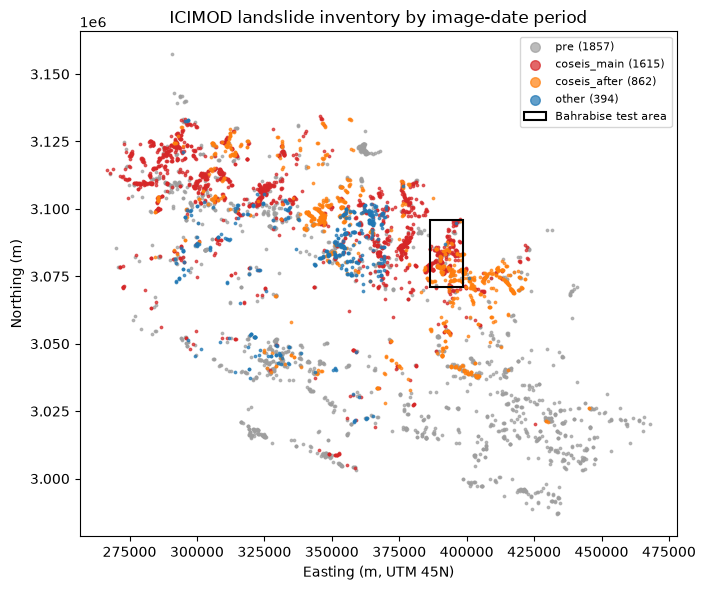

In [41]:
# 2.6 Map of the inventories
fig, ax = plt.subplots(figsize=(10, 6))
colors = {"pre": "#9e9e9e", "coseis_main": "#d62728", "coseis_after": "#ff7f0e", "other": "#1f77b4"}
for per, col in colors.items():
    sub = inv[inv["period"] == per]
    ax.scatter(sub["centroid"].x, sub["centroid"].y, s=3, c=col, label=f"{per} ({len(sub)})", alpha=.7)
bx = bah.total_bounds
ax.add_patch(plt.Rectangle((bx[0], bx[1]), bx[2] - bx[0], bx[3] - bx[1], fill=False, ec="k", lw=1.5, label="Bahrabise test area"))
ax.set_title("ICIMOD landslide inventory by image-date period")
ax.set_xlabel("Easting (m, UTM 45N)"); ax.set_ylabel("Northing (m)")
ax.legend(markerscale=4, fontsize=8)
ax.set_aspect("equal")
plt.tight_layout(); plt.savefig(FIG / "fig_inventory_periods.png", dpi=200); plt.show()


In [42]:
# 2.7 Quick checks on the other inputs: DEM, ShakeMaps, geology
with rasterio.open(PATHS["dem"]) as src:
    print("DEM:", src.width, "x", src.height, "| CRS:", src.crs, "| res:", src.res, "| nodata:", src.nodata, "| dtype:", src.dtypes[0])

def load_shakemap(path):
    """Read a USGS ShakeMap grid.xml into a DataFrame (LON, LAT, MMI, PGA, PGV, ...)."""
    text = Path(path).read_text()
    names = re.findall(r'<grid_field index="\d+" name="(\w+)"', text)
    body = text.split("<grid_data>")[1].split("</grid_data>")[0]
    return pd.DataFrame(np.loadtxt(io.StringIO(body)), columns=names)

shake_main = load_shakemap(PATHS["shake_main"])
shake_after = load_shakemap(PATHS["shake_after"])
for nm, g in [("main shock", shake_main), ("aftershock", shake_after)]:
    print(f"ShakeMap {nm}: {len(g):,} points | PGA {g.PGA.min():.2f}-{g.PGA.max():.2f} %g | MMI max {g.MMI.max()}")

geol = gpd.read_file(PATHS["geology"]).to_crs(CRS_UTM45)
print("Geology:", len(geol), "polygons,", geol["CLASS"].nunique(), "classes")


DEM: 9793 x 4925 | CRS: EPSG:4326 | res: (0.0008333333333333334, 0.0008333333333333334) | nodata: None | dtype: int16
ShakeMap main shock: 267,282 points | PGA 0.22-86.55 %g | MMI max 8.7
ShakeMap aftershock: 452,595 points | PGA 0.34-58.16 %g | MMI max 7.5
Geology: 856 polygons, 56 classes


In [43]:
# 2.8 Save the cleaned inventories for the next steps
keep = inv[inv["period"] != "bad_date"].drop(columns="centroid")
keep.to_file(OUT / "landslides_clean.gpkg", layer="inventory", driver="GPKG")
bah.to_file(OUT / "landslides_clean.gpkg", layer="bahrabise", driver="GPKG")
print("Saved", len(keep), "inventory polygons and", len(bah), "Bahrabise polygons to", OUT / "landslides_clean.gpkg")


Saved 4728 inventory polygons and 551 Bahrabise polygons to D:\Softwarica\Projects\Gorkha Earthquake Project\outputs\landslides_clean.gpkg


## Step 3. Features and sampling

This step turns the inventory into a table the models can learn from.

1. **Terrain:** the SRTM DEM is reprojected to a 90 m UTM 45N grid covering the study area (convex hull of all landslides + 2 km). Value 0 in the DEM means "outside Nepal" and is treated as nodata. From it we derive slope, aspect (as sine/cosine), plan and profile curvature, and local relief (elevation range in a 450 m window). TWI is left out because it needs a flow-routing library.
2. **Positives:** the centroid of every dated landslide: co-seismic (`coseis_main`, `coseis_after`, used by Model A) and pre-earthquake (`pre`, used by Model B in step 6).
3. **Negatives:** random points on valid DEM inside the study area, at least 150 m from **any** mapped landslide (all dates, including the 19 with unreadable dates). We draw 3 negatives per co-seismic slide: the first third (`in_1to1`) is the main 1:1 set, all of them form the 1:3 sensitivity set. Each negative gets the district of its nearest landslide, so district-grouped CV works.
4. **Shaking:** PGA and PGV from the USGS ShakeMaps, bilinearly interpolated at each point (`pga_max` = larger of main shock and aftershock), plus PGA × sin(slope).
5. **Geology:** formation from the geology map; classes with under 1% of the samples and the undocumented codes are grouped into `Other`.

Output: `outputs/features.csv` (one row per point).

In [44]:
# 3.1 Reload the cleaned inventory and fix the invalid polygons found in 2.4
from scipy import ndimage
from scipy.interpolate import RegularGridInterpolator
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from rasterio.features import geometry_mask

inv = gpd.read_file(OUT / "landslides_clean.gpkg", layer="inventory")
n_invalid = int((~inv.is_valid).sum())
inv["geometry"] = inv.geometry.make_valid()
print(f"Invalid polygons fixed: {n_invalid} -> still invalid: {int((~inv.is_valid).sum())}")

# Negatives must stay clear of EVERY mapped landslide, including the 19 with unreadable dates
all_slides = gpd.read_file(PATHS["inventory_14dist"]).to_crs(CRS_UTM45)
all_slides["geometry"] = all_slides.geometry.make_valid()
print("Polygons used for the negative-sample exclusion zone:", len(all_slides))

Invalid polygons fixed: 13 -> still invalid: 0
Polygons used for the negative-sample exclusion zone: 4747


In [45]:
# 3.2 Study area and DEM reprojected to a 90 m UTM 45N grid
RES = 90  # metres, close to the native 3-arc-second SRTM cell

# Study area = convex hull of all landslides, buffered by 2 km
study = inv.geometry.union_all().convex_hull.buffer(2000)
xmin, ymin = np.floor(np.array(study.bounds[:2]) / RES) * RES
xmax, ymax = np.ceil(np.array(study.bounds[2:]) / RES) * RES
WIDTH, HEIGHT = int((xmax - xmin) / RES), int((ymax - ymin) / RES)
GRID_TRANSFORM = from_origin(xmin, ymax, RES, RES)

dem = np.full((HEIGHT, WIDTH), np.nan, dtype="float32")
with rasterio.open(PATHS["dem"]) as src:
    reproject(source=src.read(1).astype("float32"), destination=dem,
              src_transform=src.transform, src_crs=src.crs, src_nodata=0,   # 0 = outside Nepal (no nodata tag in file)
              dst_transform=GRID_TRANSFORM, dst_crs=CRS_UTM45, dst_nodata=np.nan,
              resampling=Resampling.bilinear)

in_study = geometry_mask([study], out_shape=dem.shape, transform=GRID_TRANSFORM, invert=True)
dem[~in_study] = np.nan
print(f"Grid: {WIDTH} x {HEIGHT} cells of {RES} m | study area {study.area / 1e6:,.0f} km2")
print(f"Valid DEM cells in study area: {np.isfinite(dem).sum():,} ({np.isfinite(dem).sum() / in_study.sum():.1%})")
print(f"Elevation range: {np.nanmin(dem):.0f} - {np.nanmax(dem):.0f} m")

Grid: 2283 x 1941 cells of 90 m | study area 22,099 km2
Valid DEM cells in study area: 2,625,796 (96.2%)
Elevation range: 135 - 7351 m


In [46]:
# 3.3 Terrain derivatives from the DEM
dz_drow, dz_dx = np.gradient(dem, RES)   # axis 0 runs north -> south, axis 1 west -> east
dz_dy = -dz_drow                         # gradient towards north
grad = np.hypot(dz_dx, dz_dy)

slope = np.degrees(np.arctan(grad))
# Aspect as two continuous components (avoids the 0/360 degree jump); flat cells get 0
with np.errstate(invalid="ignore", divide="ignore"):
    aspect_sin = np.where(grad > 0, -dz_dx / grad, 0)   # eastness
    aspect_cos = np.where(grad > 0, -dz_dy / grad, 0)   # northness

# Plan and profile curvature (Florinsky 2016 formulas), in 1/100 m
p, q = dz_dx, dz_dy
r = np.gradient(dz_dx, RES, axis=1)
t = -np.gradient(dz_dy, RES, axis=0)
s = -np.gradient(dz_dx, RES, axis=0)
p2q2 = p**2 + q**2
with np.errstate(invalid="ignore", divide="ignore"):
    profile_curv = np.where(p2q2 > 0, -(p**2 * r + 2 * p * q * s + q**2 * t) / (p2q2 * (1 + p2q2) ** 1.5), 0) * 100
    plan_curv = np.where(p2q2 > 0, -(q**2 * r - 2 * p * q * s + p**2 * t) / (p2q2 * np.sqrt(1 + p2q2)), 0) * 100

# Local relief = elevation range in a 5 x 5 window (450 m)
relief = (ndimage.maximum_filter(np.nan_to_num(dem, nan=-np.inf), size=5)
          - ndimage.minimum_filter(np.nan_to_num(dem, nan=np.inf), size=5))

terrain = {"elevation": dem, "slope": slope, "aspect_sin": aspect_sin, "aspect_cos": aspect_cos,
           "plan_curv": plan_curv, "profile_curv": profile_curv, "relief": relief}
valid = np.logical_and.reduce([np.isfinite(a) for a in terrain.values()])
for a in terrain.values():
    a[~valid] = np.nan
print(f"Cells with all terrain features: {valid.sum():,}")
pd.DataFrame({k: pd.Series(v[valid]).describe(percentiles=[.5]) for k, v in terrain.items()}).T.round(3)

Cells with all terrain features: 2,612,676


,count,mean,std,min,50%,max
elevation,2612676.0,1835.972,1247.569,135.216,1495.993,7351.139
slope,2612676.0,23.743,11.161,0.000,23.812,82.736
aspect_sin,2612676.0,-0.022,0.695,-1.000,-0.040,1.000
aspect_cos,2612676.0,-0.044,0.717,-1.000,-0.100,1.000
plan_curv,2612676.0,0.006,0.156,-2.891,0.002,1.893
profile_curv,2612676.0,-0.006,0.122,-2.184,-0.004,1.621
relief,2612676.0,203.417,102.328,1.513,194.380,1896.646


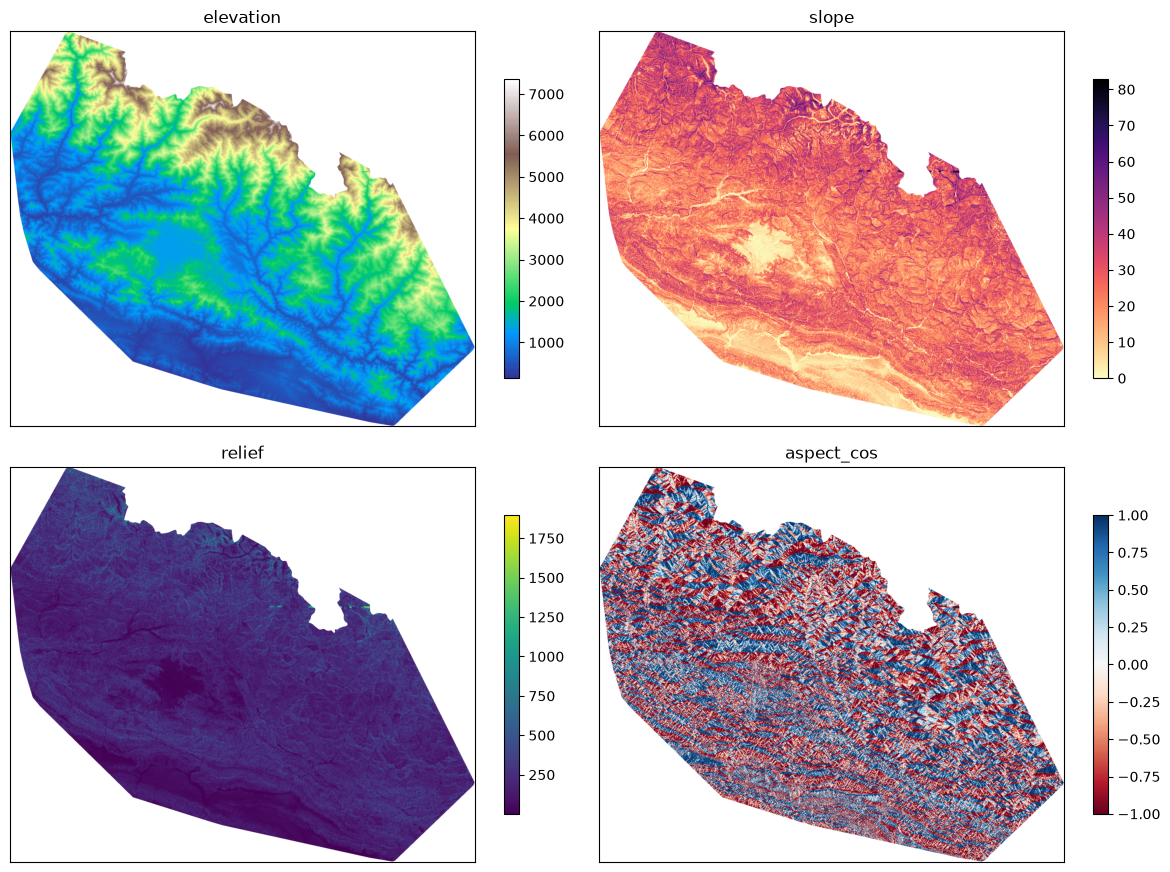

In [47]:
# 3.4 Terrain maps
extent = [xmin, xmax, ymin, ymax]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (key, cmap) in zip(axes.flat, [("elevation", "terrain"), ("slope", "magma_r"), ("relief", "viridis"), ("aspect_cos", "RdBu")]):
    im = ax.imshow(terrain[key], extent=extent, cmap=cmap)
    ax.set_title(key); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, shrink=.7)
plt.tight_layout(); plt.savefig(FIG / "fig_terrain.png", dpi=150); plt.show()

In [48]:
# 3.5 Sample points: landslide centroids (positives) and random non-landslide points (negatives)
rng = np.random.default_rng(SEED)

labelled = inv[inv["period"].isin(["pre", "coseis_main", "coseis_after"])]
pos = gpd.GeoDataFrame({"period": labelled["period"].to_numpy(), "district": labelled["district"].to_numpy()},
                       geometry=labelled.geometry.centroid.to_numpy(), crs=CRS_UTM45)

# Draw 3x as many negatives as co-seismic slides: the first n_coseismic are the 1:1 set, all of them the 1:3 set
n_coseismic = int(pos["period"].str.startswith("coseis").sum())
N_NEG = 3 * n_coseismic
cells = rng.choice(np.flatnonzero(valid), size=int(N_NEG * 1.3), replace=False)
rows, cols = np.unravel_index(cells, valid.shape)
cand = gpd.GeoSeries(gpd.points_from_xy(xmin + (cols + rng.random(len(cols))) * RES,     # random spot inside the cell
                                        ymax - (rows + rng.random(len(rows))) * RES), crs=CRS_UTM45)
too_close = np.unique(all_slides.sindex.query(cand, predicate="dwithin", distance=NEG_BUFFER_M)[0])
cand = cand.drop(index=too_close)
print(f"Candidates rejected (< {NEG_BUFFER_M} m from a landslide): {len(too_close):,}")
assert len(cand) >= N_NEG, "not enough negatives: increase the 1.3 oversampling factor"

neg = gpd.GeoDataFrame({"period": ["none"] * N_NEG}, geometry=cand.iloc[:N_NEG].to_numpy(), crs=CRS_UTM45)
# No district boundary layer: give each negative the district of its nearest mapped landslide
neg = gpd.sjoin_nearest(neg, inv[["district", "geometry"]], how="left")
neg = neg[~neg.index.duplicated()].drop(columns="index_right")
neg["in_1to1"] = np.arange(len(neg)) < n_coseismic
pos["in_1to1"] = True

samples = pd.concat([pos, neg], ignore_index=True)
print(samples.groupby("period")["in_1to1"].agg(n="size", in_1to1="sum").to_string())

Candidates rejected (< 150 m from a landslide): 237
                 n  in_1to1
period                     
coseis_after   862      862
coseis_main   1615     1615
none          7431     2477
pre           1857     1857


In [49]:
# 3.6 Extract features at every sample point: terrain, ground shaking, geology
def sample_grid(arr, x, y):
    """Nearest-cell value of a study-grid array at UTM points (NaN outside the grid)."""
    c = np.floor((x - xmin) / RES).astype(int)
    r = np.floor((ymax - y) / RES).astype(int)
    ok = (r >= 0) & (r < HEIGHT) & (c >= 0) & (c < WIDTH)
    out = np.full(len(x), np.nan, dtype="float32")
    out[ok] = arr[r[ok], c[ok]]
    return out

def shakemap_interpolator(df, field):
    """Bilinear interpolator over a ShakeMap grid (rows in the file run north -> south)."""
    lons, lats = np.unique(df["LON"]), np.unique(df["LAT"])
    assert len(lons) * len(lats) == len(df), "ShakeMap is not a regular grid"
    grid = df.sort_values(["LAT", "LON"])[field].to_numpy().reshape(len(lats), len(lons))
    return RegularGridInterpolator((lats, lons), grid, bounds_error=False, fill_value=np.nan)

SHAKE = {"pga_main": shakemap_interpolator(shake_main, "PGA"), "pgv_main": shakemap_interpolator(shake_main, "PGV"),
         "pga_after": shakemap_interpolator(shake_after, "PGA")}

def extract_features(points):
    """Feature table for a GeoDataFrame of points in UTM 45N."""
    x, y = points.geometry.x.to_numpy(), points.geometry.y.to_numpy()
    ll = points.geometry.to_crs(CRS_WGS84)
    f = pd.DataFrame({"x": x, "y": y, "lon": ll.x.to_numpy(), "lat": ll.y.to_numpy()}, index=points.index)
    for k, arr in terrain.items():
        f[k] = sample_grid(arr, x, y)
    latlon = np.c_[f["lat"], f["lon"]]
    for k, interp in SHAKE.items():
        f[k] = interp(latlon)
    f["pga_max"] = f[["pga_main", "pga_after"]].max(axis=1)
    f["pga_sin_slope"] = f["pga_max"] / 100 * np.sin(np.radians(f["slope"]))   # PGA (g) x sin(slope), as in ref. [3]
    geo = gpd.sjoin(points[["geometry"]], geol[["CLASS", "geometry"]], how="left", predicate="within")
    f["geology"] = geo.loc[~geo.index.duplicated(), "CLASS"].reindex(points.index).fillna("No Data").replace("", "No Data")
    return f

feat = extract_features(samples)
samples = pd.concat([samples.drop(columns="geometry"), feat], axis=1)
print("Feature table:", samples.shape, "| missing values:", int(samples.isna().sum().sum()))

Feature table: (11765, 20) | missing values: 0


In [50]:
# 3.7 Group rare and undocumented geology classes into "Other"
# Grouping uses only class counts (not labels), so it does not leak target information into CV
counts = samples["geology"].value_counts()
MIN_GEO = int(0.01 * len(samples))   # a class needs >= 1% of the samples to keep its own name
undocumented = {"No Data", "Ba", "Bb", "Bu", "Cr", "Cs", "Du", "Gh", "Gn", "Pa", "Rb", "Sh"}
keep_geo = [c for c in counts.index if counts[c] >= MIN_GEO and c not in undocumented]
samples["geology"] = samples["geology"].where(samples["geology"].isin(keep_geo), "Other")
print(f"Geology classes in the samples: {counts.size} -> {samples['geology'].nunique()}")
pd.crosstab(samples["geology"], samples["period"]).reindex(columns=["coseis_main", "coseis_after", "pre", "none"])

Geology classes in the samples: 39 -> 21


period,coseis_main,coseis_after,pre,none
geology,,,,
Galyang Formation,49,20,59,175
Ghanapokhara Formation,140,84,57,180
Granites,7,8,53,302
Himal Group,317,244,158,885
Lakharpata Formation,38,29,36,114
Lower Siwalik,1,0,82,254
Markhu Formation,2,6,42,84
Middle Siwalik2,4,0,95,212
Naudanda Formation,40,16,52,42


,elevation,slope,relief,pga_main,pga_after,pgv_main
period,,,,,,
coseis_main,1702.5,36.4,300.8,61.2,10.3,47.3
coseis_after,1898.2,34.7,278.0,60.4,21.0,46.5
pre,1276.6,29.9,231.5,52.7,13.0,38.5
none,1498.8,23.9,194.2,54.5,13.4,40.5


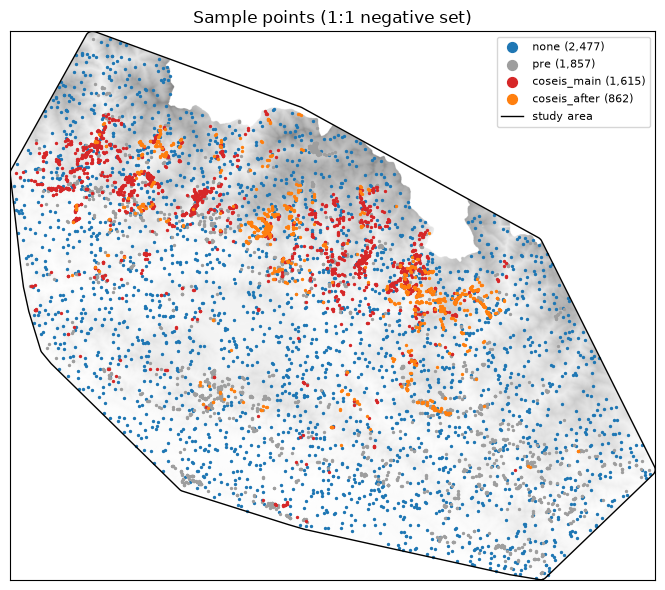

In [51]:
# 3.8 Sanity check: landslides should sit on steeper, higher-relief, harder-shaken ground than the negatives
check_cols = ["elevation", "slope", "relief", "pga_main", "pga_after", "pgv_main"]
display(samples.groupby("period")[check_cols].median().astype(float).reindex(["coseis_main", "coseis_after", "pre", "none"]).round(1))

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(terrain["elevation"], extent=extent, cmap="Greys", alpha=.5)
for per, col in {"none": "#1f77b4", "pre": "#9e9e9e", "coseis_main": "#d62728", "coseis_after": "#ff7f0e"}.items():
    sub = samples[(samples["period"] == per) & samples["in_1to1"]]
    ax.scatter(sub["x"], sub["y"], s=2, c=col, label=f"{per} ({len(sub):,})")
ax.plot(*study.exterior.xy, "k-", lw=1, label="study area")
ax.set_title("Sample points (1:1 negative set)"); ax.set_xticks([]); ax.set_yticks([])
ax.legend(markerscale=5, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig_samples.png", dpi=200); plt.show()

In [52]:
# 3.9 Save the feature table
samples.to_csv(OUT / "features.csv", index=False)
print(f"Saved {len(samples):,} rows x {samples.shape[1]} columns to", OUT / "features.csv")
print("Columns:", ", ".join(samples.columns))

Saved 11,765 rows x 20 columns to D:\Softwarica\Projects\Gorkha Earthquake Project\outputs\features.csv
Columns: period, district, in_1to1, x, y, lon, lat, elevation, slope, aspect_sin, aspect_cos, plan_curv, profile_curv, relief, pga_main, pgv_main, pga_after, pga_max, pga_sin_slope, geology


## Step 4. Exploratory analysis and PCA

Exploration of the **Model A** dataset: 2,477 co-seismic landslides vs the 2,477 negatives of the 1:1 set (read from `outputs/features.csv`, so this step can run without re-running step 3).

1. **Single-feature separation:** median per class and a single-feature AUC (Mann-Whitney U / n₁n₀). An AUC of 0.5 means the feature alone can't tell the classes apart; values far from 0.5 in either direction mean strong separation.
2. **Distributions** of every numeric feature for landslide vs non-landslide points.
3. **Geology:** share of landslide points in each rock class. This is exploration only; the models encode geology inside the CV folds to avoid leakage.
4. **Pearson correlation** to check multicollinearity (important for Logistic Regression).
5. **PCA** on the standardised features: how many independent directions the data really has, and whether the classes separate on the first components.
6. **Feature set** chosen for step 5.

In [53]:
# 4.1 Load the feature table and build the Model A dataset (co-seismic landslides vs 1:1 negatives)
from scipy.stats import mannwhitneyu
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

samples = pd.read_csv(OUT / "features.csv")
TERRAIN = ["elevation", "slope", "aspect_sin", "aspect_cos", "plan_curv", "profile_curv", "relief"]
SHAKING = ["pga_main", "pga_after", "pga_max", "pgv_main", "pga_sin_slope"]
NUMERIC = TERRAIN + SHAKING

dfA = samples[samples["period"].str.startswith("coseis") | ((samples["period"] == "none") & samples["in_1to1"])].copy()
dfA["landslide"] = dfA["period"].str.startswith("coseis").astype(int)
print(dfA["landslide"].value_counts().rename({1: "landslide", 0: "non-landslide"}).to_string())

landslide
landslide        2477
non-landslide    2477


In [54]:
# 4.2 How well does each feature separate the classes on its own?
# Single-feature AUC = Mann-Whitney U / (n1 * n0): 0.5 = no separation, 1.0 (or 0.0) = perfect
ls, nls = dfA[dfA["landslide"] == 1], dfA[dfA["landslide"] == 0]
rows = []
for f in NUMERIC:
    u, pval = mannwhitneyu(ls[f], nls[f])
    rows.append({"feature": f, "median_landslide": ls[f].median(), "median_non_landslide": nls[f].median(),
                 "single_feature_AUC": u / (len(ls) * len(nls)), "p_value": pval})
univariate = pd.DataFrame(rows).set_index("feature")
univariate["separation"] = (univariate["single_feature_AUC"] - 0.5).abs() + 0.5   # direction-free strength
univariate = univariate.sort_values("separation", ascending=False)
univariate.to_csv(OUT / "table_univariate.csv")
univariate.round(3)

,median_landslide,median_non_landslide,single_feature_AUC,p_value,separation
feature,,,,,
pga_sin_slope,0.353,0.205,0.834,0.000,0.834
slope,35.723,24.069,0.773,0.000,0.773
pga_main,60.864,54.817,0.770,0.000,0.770
pga_max,60.864,54.819,0.770,0.000,0.770
relief,292.960,194.228,0.766,0.000,0.766
pgv_main,46.964,40.991,0.757,0.000,0.757
profile_curv,-0.025,0.000,0.408,0.000,0.592
aspect_cos,-0.464,-0.129,0.419,0.000,0.581
elevation,1771.683,1497.245,0.568,0.000,0.568


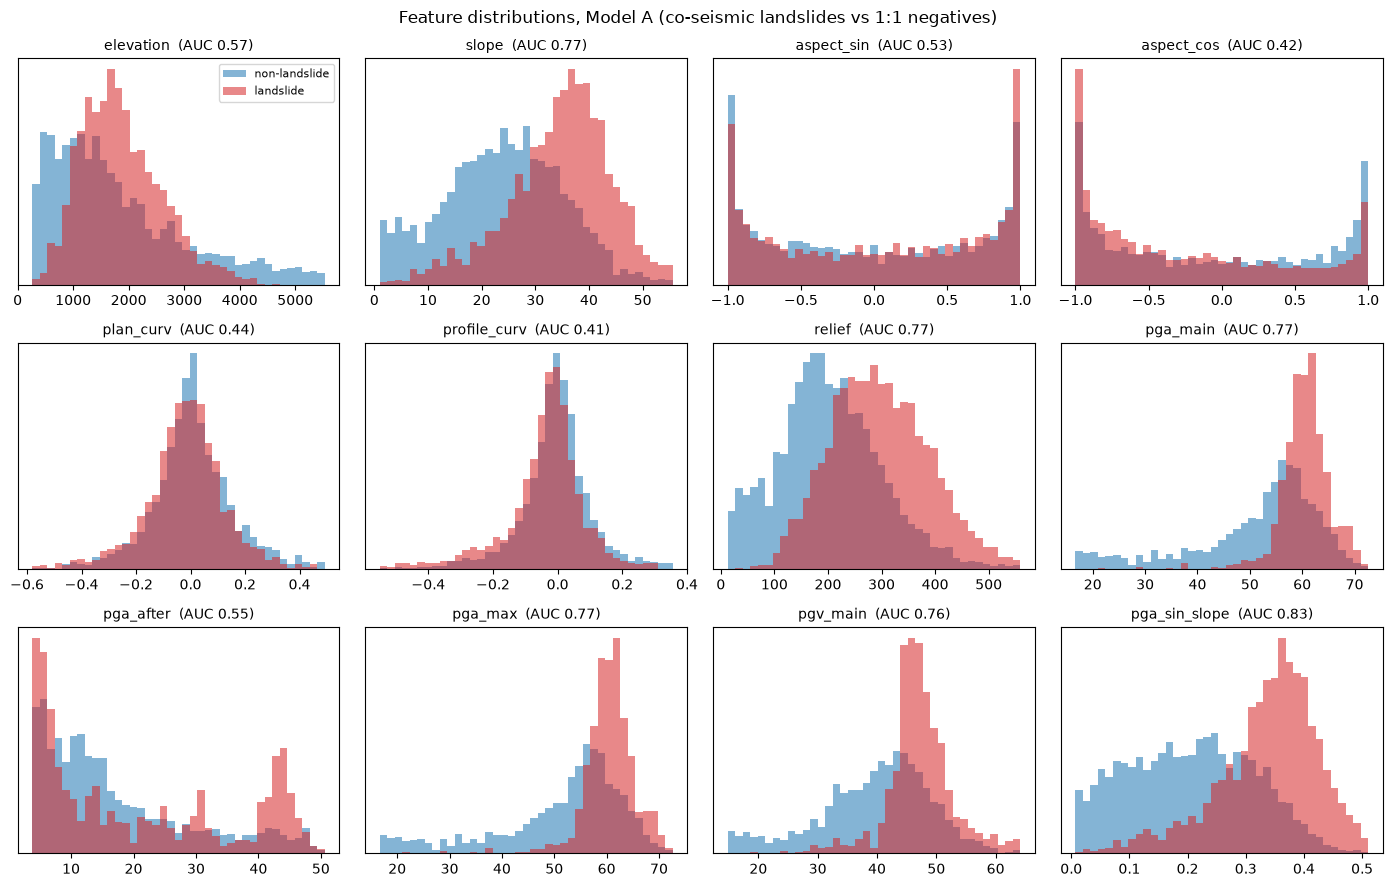

In [55]:
# 4.3 Distributions: landslide vs non-landslide
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, f in zip(axes.flat, NUMERIC):
    bins = np.linspace(*dfA[f].quantile([.005, .995]), 40)   # trim extreme tails for readability
    ax.hist(nls[f], bins=bins, density=True, alpha=.55, color="#1f77b4", label="non-landslide")
    ax.hist(ls[f], bins=bins, density=True, alpha=.55, color="#d62728", label="landslide")
    ax.set_title(f"{f}  (AUC {univariate.loc[f, 'single_feature_AUC']:.2f})", fontsize=10)
    ax.set_yticks([])
axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(NUMERIC):]:
    ax.axis("off")
plt.suptitle("Feature distributions, Model A (co-seismic landslides vs 1:1 negatives)")
plt.tight_layout(); plt.savefig(FIG / "fig_distributions.png", dpi=200); plt.show()

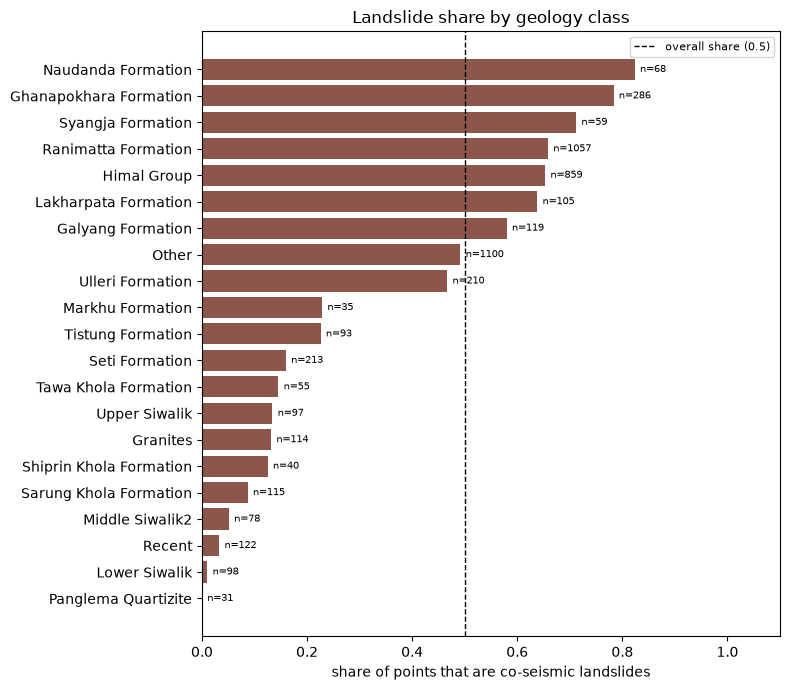

In [56]:
# 4.4 Landslide share per geology class (EDA only: the models encode geology inside the CV folds)
geo = dfA.groupby("geology")["landslide"].agg(n="size", landslide_share="mean").sort_values("landslide_share")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(geo.index, geo["landslide_share"], color="#8c564b")
ax.axvline(dfA["landslide"].mean(), color="k", ls="--", lw=1, label="overall share (0.5)")
for i, (n, sh) in enumerate(zip(geo["n"], geo["landslide_share"])):
    ax.text(sh + .01, i, f"n={n}", va="center", fontsize=7)
ax.set_xlabel("share of points that are co-seismic landslides"); ax.set_xlim(0, 1.1)
ax.set_title("Landslide share by geology class"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig_geology_share.png", dpi=200); plt.show()

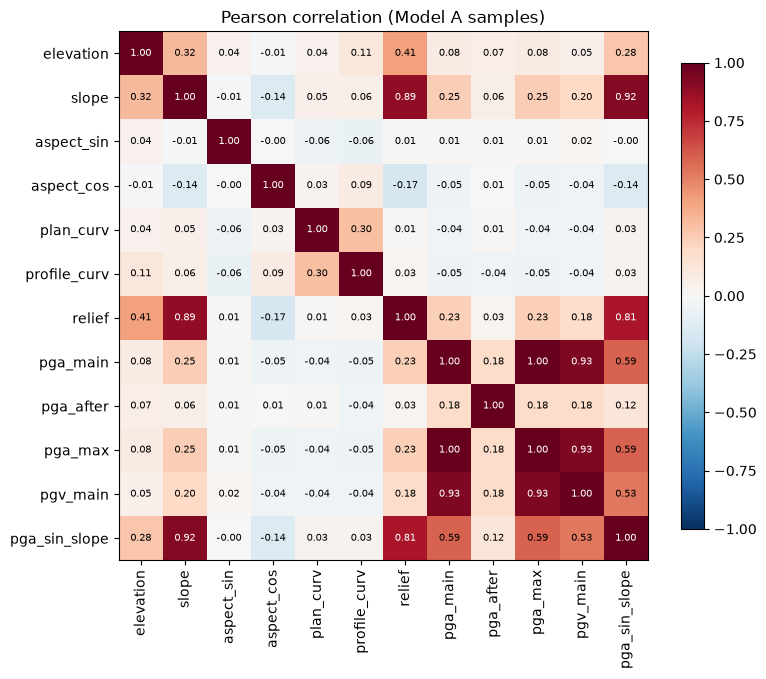

Pairs with |r| > 0.7:
pga_main  pga_max          1.000
pga_max   pgv_main         0.935
pga_main  pgv_main         0.935
slope     pga_sin_slope    0.917
          relief           0.891
relief    pga_sin_slope    0.814


In [57]:
# 4.5 Pearson correlation between the numeric features (multicollinearity check)
corr = dfA[NUMERIC].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=90); ax.set_yticks(range(len(NUMERIC)), NUMERIC)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > .6 else "black")
plt.colorbar(im, ax=ax, shrink=.8); ax.set_title("Pearson correlation (Model A samples)")
plt.tight_layout(); plt.savefig(FIG / "fig_correlation.png", dpi=200); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("r")
print("Pairs with |r| > 0.7:")
print(pairs[pairs.abs() > .7].sort_values(key=abs, ascending=False).round(3).to_string())

Explained variance by component: [0.334 0.171 0.111 0.086 0.08  0.078 0.065 0.056 0.011 0.007 0.001 0.   ]
Components needed for 90% of the variance: 7 of 12


,PC1,PC2,PC3,PC4
elevation,0.16,0.30,0.07,0.38
slope,0.36,0.44,-0.07,-0.04
aspect_sin,0.01,-0.02,-0.21,0.70
aspect_cos,-0.08,-0.09,0.30,0.45
plan_curv,-0.00,0.12,0.63,-0.06
profile_curv,-0.00,0.15,0.65,0.01
relief,0.34,0.45,-0.12,-0.01
pga_main,0.42,-0.36,0.07,-0.02
pga_after,0.11,-0.11,0.04,0.39
pga_max,0.42,-0.36,0.07,-0.02


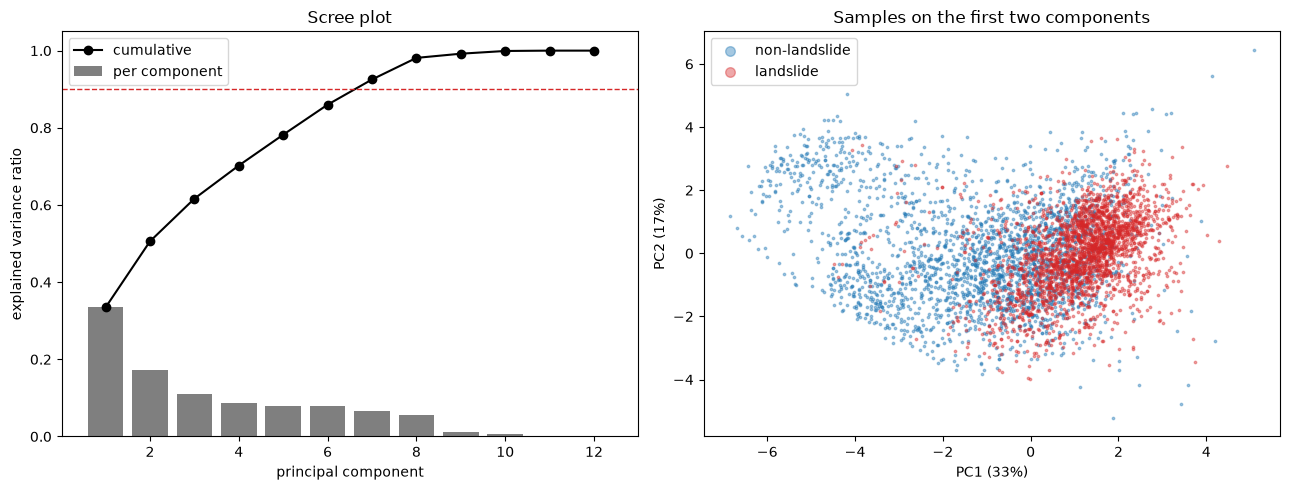

In [58]:
# 4.6 PCA on the standardised numeric features (exploration of the correlation structure)
Z = StandardScaler().fit_transform(dfA[NUMERIC])
pca = PCA(random_state=SEED).fit(Z)
evr = pca.explained_variance_ratio_
print("Explained variance by component:", np.round(evr, 3))
print(f"Components needed for 90% of the variance: {np.searchsorted(np.cumsum(evr), .90) + 1} of {len(NUMERIC)}")

loadings = pd.DataFrame(pca.components_[:4].T, index=NUMERIC, columns=[f"PC{i}" for i in range(1, 5)])
display(loadings.round(2))

scores = pca.transform(Z)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.bar(range(1, len(evr) + 1), evr, color="#7f7f7f", label="per component")
ax1.plot(range(1, len(evr) + 1), np.cumsum(evr), "o-", color="k", label="cumulative")
ax1.axhline(.9, ls="--", lw=1, color="#d62728")
ax1.set_xlabel("principal component"); ax1.set_ylabel("explained variance ratio"); ax1.legend(); ax1.set_title("Scree plot")
for lab, col, name in [(0, "#1f77b4", "non-landslide"), (1, "#d62728", "landslide")]:
    m = dfA["landslide"].to_numpy() == lab
    ax2.scatter(scores[m, 0], scores[m, 1], s=3, alpha=.4, c=col, label=name)
ax2.set_xlabel(f"PC1 ({evr[0]:.0%})"); ax2.set_ylabel(f"PC2 ({evr[1]:.0%})"); ax2.legend(markerscale=4)
ax2.set_title("Samples on the first two components")
plt.tight_layout(); plt.savefig(FIG / "fig_pca.png", dpi=200); plt.show()

In [59]:
# 4.7 Feature set for the models (decided from 4.5)
# pga_max duplicates pga_main (r = 1.00: the main shock shook harder everywhere in the study area)
# pgv_main is near-duplicate of pga_main (r = 0.94) -> dropped to limit multicollinearity in LR
# pga_sin_slope is kept although r = 0.92 with slope: it is the strongest single feature and gives LR the
# slope x shaking interaction it cannot learn by itself; RF and SVM are not hurt by the overlap
DROP = ["pga_max", "pgv_main"]
FEATURES_NUM = [f for f in NUMERIC if f not in DROP]
FEATURES_CAT = ["geology"]
print("Numeric features:", FEATURES_NUM)
print("Categorical features:", FEATURES_CAT)

Numeric features: ['elevation', 'slope', 'aspect_sin', 'aspect_cos', 'plan_curv', 'profile_curv', 'relief', 'pga_main', 'pga_after', 'pga_sin_slope']
Categorical features: ['geology']


## Step 5. Models and validation

**Model A:** co-seismic landslides vs the 1:1 negatives, features from cell 4.7 (10 numeric + geology).

| Method | Notes | Hyperparameter grid |
|---|---|---|
| Frequency Ratio (baseline) | sum of class FRs over slope, relief, PGA (10 quantile bins each) and geology | none |
| Logistic Regression | L2 penalty, balanced class weights | C ∈ {0.001, 0.01, 0.1, 1, 10} |
| SVM (RBF) | balanced class weights; Platt scaling for probabilities | C ∈ {0.1, 1, 10, 100}, γ ∈ {scale, 0.001, 0.01, 0.1} |
| Random Forest | 300 trees, balanced class weights | max_depth ∈ {5, 10, 20, None}, min_samples_leaf ∈ {1, 5}, max_features ∈ {sqrt, 0.5} |

**Validation: nested leave-one-district-out CV.** A random split would put neighbouring (spatially correlated) points into both train and test sets and inflate the scores. Here each district is held out once, so every score measures transfer to an area the model has never seen. The five districts with fewer than 25 co-seismic slides (Kathmandu, Okhaldhunga, Lalitpur, Sindhuli, Makwanpur) form one group, giving 9 outer folds. Inside each outer training set, a 3-fold `GroupKFold` grid search picks the hyperparameters by ROC-AUC. Scaling, one-hot encoding and FR classes are all fitted on training folds only.

**Metrics:** ROC-AUC, PR-AUC (average precision), accuracy, precision, recall, F1 and Cohen's kappa, at a 0.5 probability threshold (FR: neutral index of 1 per factor). Reported both pooled over all held-out predictions and as mean ± sd of the per-fold AUC.

Runtime about 3–4 minutes. `run_nested_cv()` is reused in step 6.

In [60]:
# 5.1 Cross-validation groups: one fold per district, the 5 districts with < 25 co-seismic slides merged into one
import time
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV, GroupKFold, LeaveOneGroupOut
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score,
                             f1_score, cohen_kappa_score, roc_curve, precision_recall_curve, confusion_matrix)

SMALL_DISTRICTS = ["kathmandu", "okhaldhunga", "lalitpur", "sindhuli", "makwanpur"]
def cv_group(district):
    return district.where(~district.isin(SMALL_DISTRICTS), "small_districts")

dfA["cv_group"] = cv_group(dfA["district"])
group_table = pd.crosstab(dfA["cv_group"], dfA["landslide"]).rename(columns={0: "non_landslide", 1: "landslide"}).rename_axis(columns=None)
group_table.sort_values("landslide", ascending=False)

,non_landslide,landslide
cv_group,,
sindhupalchowk,330,986
dhading,281,394
gorkha,228,309
nuwakot,135,215
rasuwa,147,206
dolakha,206,191
small_districts,816,67
ramechhap,170,59
kaverpalanchowk,164,50


In [61]:
# 5.2 Frequency Ratio baseline (classical statistical method, fitted on the training fold only)
# FR of a class = share of training landslides in that class / share of all training points in that class.
# The FR index of a point is the sum of its class FRs over the factors; 1 per factor = average susceptibility.
FR_FACTORS = {"slope": 10, "relief": 10, "pga_main": 10, "geology": None}   # number of quantile bins (None = categories)

def fr_fit_predict(train, test, factors=FR_FACTORS):
    score = np.zeros(len(test))
    is_ls = train["landslide"].to_numpy() == 1
    for f, nbins in factors.items():
        if nbins:
            edges = np.unique(np.quantile(train[f], np.linspace(0, 1, nbins + 1)))[1:-1]
            tr_cls, te_cls = np.digitize(train[f], edges), np.digitize(test[f], edges)
        else:
            tr_cls, te_cls = train[f].to_numpy(), test[f].to_numpy()
        n_cls = pd.Series(tr_cls).value_counts()
        n_ls = pd.Series(tr_cls[is_ls]).value_counts().reindex(n_cls.index, fill_value=0)
        fr = ((n_ls + 1) / (is_ls.sum() + len(n_cls))) / ((n_cls + 1) / (len(train) + len(n_cls)))   # +1 smoothing
        score += pd.Series(te_cls).map(fr).fillna(1.0).to_numpy()                                    # unseen class -> neutral
    return score

In [62]:
# 5.3 The three classifiers as pipelines (scaling and one-hot encoding are fitted inside each training fold)
def make_preprocessor(features_num, features_cat):
    return ColumnTransformer([("num", StandardScaler(), features_num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat)])

MODELS = {
    "LR":  (LogisticRegression(max_iter=5000, class_weight="balanced"),
            {"clf__C": [0.001, 0.01, 0.1, 1, 10]}),
    "SVM": (SVC(kernel="rbf", class_weight="balanced", random_state=SEED),
            {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.001, 0.01, 0.1]}),
    "RF":  (RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=1),   # GridSearchCV already runs in parallel
            {"clf__max_depth": [5, 10, 20, None], "clf__min_samples_leaf": [1, 5], "clf__max_features": ["sqrt", 0.5]}),
}
for name, (est, grid) in MODELS.items():
    print(f"{name}: {np.prod([len(v) for v in grid.values()])} grid combinations {grid}")

LR: 5 grid combinations {'clf__C': [0.001, 0.01, 0.1, 1, 10]}
SVM: 16 grid combinations {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': ['scale', 0.001, 0.01, 0.1]}
RF: 16 grid combinations {'clf__max_depth': [5, 10, 20, None], 'clf__min_samples_leaf': [1, 5], 'clf__max_features': ['sqrt', 0.5]}


In [63]:
# 5.4 Nested leave-one-district-out CV
# Outer loop: each CV group is held out once (tests spatial transfer to an unseen district).
# Inner loop: GridSearchCV with 3-fold GroupKFold on the remaining districts picks the hyperparameters (ROC-AUC).
# SVM has no predict_proba: it is tuned on its decision function (fast), then the best model is refitted with
# Platt scaling (sigmoid calibration, internal 5-fold CV) to turn its scores into probabilities.
def run_nested_cv(df, features_num, features_cat=FEATURES_CAT, models=MODELS, fr_factors=FR_FACTORS, label=""):
    """Returns out-of-fold predictions (one row per point per model) and the chosen hyperparameters per fold."""
    X, y, groups = df[features_num + features_cat], df["landslide"].to_numpy(), df["cv_group"].to_numpy()
    oof, params = [], []
    for fold, (tr, te) in enumerate(LeaveOneGroupOut().split(X, y, groups)):
        held_out = groups[te][0]
        base = {"idx": df.index[te], "cv_group": held_out, "y": y[te]}
        if fr_factors:
            oof.append(pd.DataFrame({**base, "model": "FR", "score": fr_fit_predict(df.iloc[tr], df.iloc[te], fr_factors),
                                     "threshold": len(fr_factors)}))
        for name, (est, grid) in models.items():
            t0 = time.time()
            pipe = Pipeline([("prep", make_preprocessor(features_num, features_cat)), ("clf", clone(est))])
            search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=GroupKFold(n_splits=3), n_jobs=-1)
            search.fit(X.iloc[tr], y[tr], groups=groups[tr])
            best = search.best_estimator_
            if name == "SVM":
                best = CalibratedClassifierCV(clone(best), method="sigmoid", ensemble=False).fit(X.iloc[tr], y[tr])
            oof.append(pd.DataFrame({**base, "model": name, "score": best.predict_proba(X.iloc[te])[:, 1], "threshold": 0.5}))
            params.append({"cv_group": held_out, "model": name, "inner_auc": search.best_score_,
                           **{k.replace("clf__", ""): str(v) for k, v in search.best_params_.items()}, "seconds": time.time() - t0})
        print(f"{label} fold {fold + 1}: held out {held_out:<16} done")
    return pd.concat(oof, ignore_index=True), pd.DataFrame(params)

t0 = time.time()
oofA, paramsA = run_nested_cv(dfA, FEATURES_NUM, label="Model A")
print(f"Total time: {(time.time() - t0) / 60:.1f} min")
oofA.to_csv(OUT / "oof_modelA.csv", index=False)
paramsA.to_csv(OUT / "best_params_modelA.csv", index=False)

Model A fold 1: held out dhading          done
Model A fold 2: held out dolakha          done
Model A fold 3: held out gorkha           done
Model A fold 4: held out kaverpalanchowk  done
Model A fold 5: held out nuwakot          done
Model A fold 6: held out ramechhap        done
Model A fold 7: held out rasuwa           done
Model A fold 8: held out sindhupalchowk   done
Model A fold 9: held out small_districts  done
Total time: 3.3 min


In [64]:
# 5.5 Results: pooled out-of-fold metrics (all held-out districts together)
def metrics(y, score, threshold):
    pred = (score >= threshold).astype(int)
    return {"ROC_AUC": roc_auc_score(y, score), "PR_AUC": average_precision_score(y, score),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred), "recall": recall_score(y, pred),
            "F1": f1_score(y, pred), "kappa": cohen_kappa_score(y, pred)}

def results_table(oof):
    pooled = pd.DataFrame({m: metrics(g["y"], g["score"], g["threshold"].iloc[0]) for m, g in oof.groupby("model", sort=False)}).T
    fold_auc = oof.groupby(["model", "cv_group"]).apply(lambda g: roc_auc_score(g["y"], g["score"])).unstack().reindex(pooled.index)
    pooled["fold_AUC_mean"], pooled["fold_AUC_sd"] = fold_auc.mean(axis=1), fold_auc.std(axis=1)
    return pooled, fold_auc

resultsA, fold_aucA = results_table(oofA)
resultsA.to_csv(OUT / "table_results_modelA.csv")
display(resultsA.round(3))
print("ROC-AUC per held-out district:")
display(fold_aucA.T.join(group_table["landslide"].rename("n_landslides")).sort_values("n_landslides", ascending=False).round(3))

,ROC_AUC,PR_AUC,accuracy,precision,recall,F1,kappa,fold_AUC_mean,fold_AUC_sd
FR,0.855,0.843,0.763,0.729,0.838,0.780,0.527,0.790,0.056
LR,0.864,0.843,0.789,0.777,0.810,0.793,0.577,0.844,0.059
SVM,0.877,0.860,0.800,0.788,0.822,0.804,0.600,0.865,0.067
RF,0.890,0.877,0.812,0.816,0.806,0.811,0.624,0.854,0.065


ROC-AUC per held-out district:


,FR,LR,SVM,RF,n_landslides
cv_group,,,,,
sindhupalchowk,0.771,0.762,0.810,0.828,986
dhading,0.793,0.815,0.853,0.829,394
gorkha,0.804,0.865,0.892,0.879,309
nuwakot,0.826,0.857,0.889,0.890,215
rasuwa,0.788,0.875,0.880,0.877,206
dolakha,0.740,0.894,0.917,0.909,191
small_districts,0.703,0.758,0.722,0.731,67
ramechhap,0.905,0.935,0.955,0.946,59
kaverpalanchowk,0.783,0.839,0.862,0.794,50


In [65]:
# 5.6 Chosen hyperparameters per outer fold (stability check)
for name in MODELS:
    sub = paramsA[paramsA["model"] == name].dropna(axis=1, how="all").drop(columns="model")
    print(f"\n{name}  (mean fit time per fold {sub['seconds'].mean():.0f} s)")
    print(sub.drop(columns="seconds").round(3).to_string(index=False))


LR  (mean fit time per fold 1 s)
       cv_group  inner_auc    C
        dhading      0.844 0.01
        dolakha      0.834 0.01
         gorkha      0.835 0.01
kaverpalanchowk      0.843 0.01
        nuwakot      0.837 0.01
      ramechhap      0.835 0.01
         rasuwa      0.836 0.01
 sindhupalchowk      0.854    1
small_districts      0.826 0.01

SVM  (mean fit time per fold 7 s)
       cv_group  inner_auc   C gamma
        dhading      0.860  10  0.01
        dolakha      0.843   1  0.01
         gorkha      0.860  10  0.01
kaverpalanchowk      0.855   1  0.01
        nuwakot      0.842   1  0.01
      ramechhap      0.848  10  0.01
         rasuwa      0.842 0.1  0.01
 sindhupalchowk      0.869  10  0.01
small_districts      0.854  10  0.01

RF  (mean fit time per fold 15 s)
       cv_group  inner_auc max_depth max_features min_samples_leaf
        dhading      0.862        10         sqrt                5
        dolakha      0.859        10         sqrt                1
     

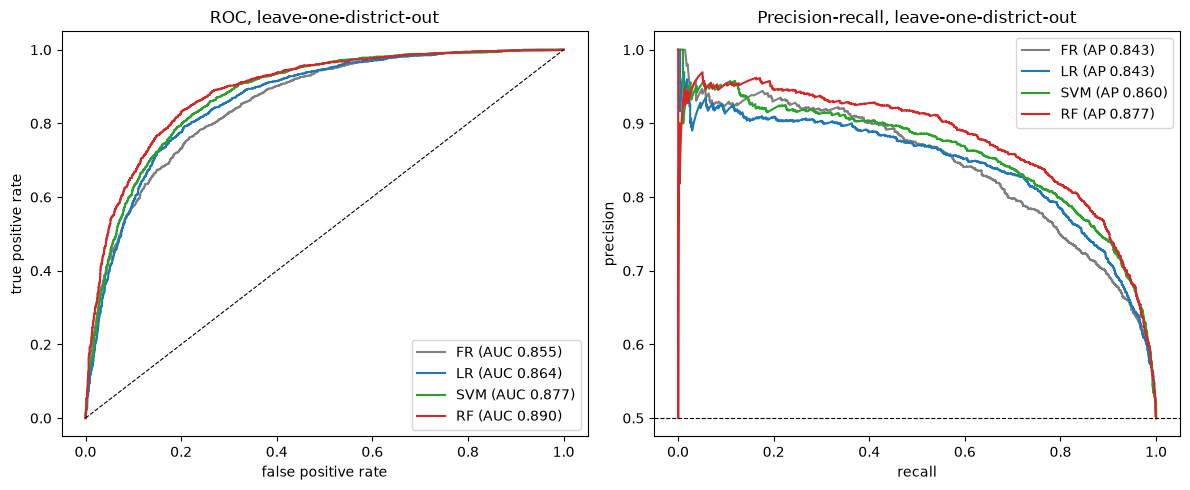

In [66]:
# 5.7 ROC and precision-recall curves (pooled out-of-fold predictions)
COLORS = {"FR": "#7f7f7f", "LR": "#1f77b4", "SVM": "#2ca02c", "RF": "#d62728"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for name, g in oofA.groupby("model", sort=False):
    fpr, tpr, _ = roc_curve(g["y"], g["score"])
    prec, rec, _ = precision_recall_curve(g["y"], g["score"])
    ax1.plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {resultsA.loc[name, 'ROC_AUC']:.3f})")
    ax2.plot(rec, prec, color=COLORS[name], label=f"{name} (AP {resultsA.loc[name, 'PR_AUC']:.3f})")
ax1.plot([0, 1], [0, 1], "k--", lw=.8)
ax1.set_xlabel("false positive rate"); ax1.set_ylabel("true positive rate"); ax1.set_title("ROC, leave-one-district-out")
ax2.axhline(oofA.query("model == 'LR'")["y"].mean(), color="k", ls="--", lw=.8)
ax2.set_xlabel("recall"); ax2.set_ylabel("precision"); ax2.set_title("Precision-recall, leave-one-district-out")
ax1.legend(); ax2.legend()
plt.tight_layout(); plt.savefig(FIG / "fig_roc_pr_modelA.png", dpi=200); plt.show()

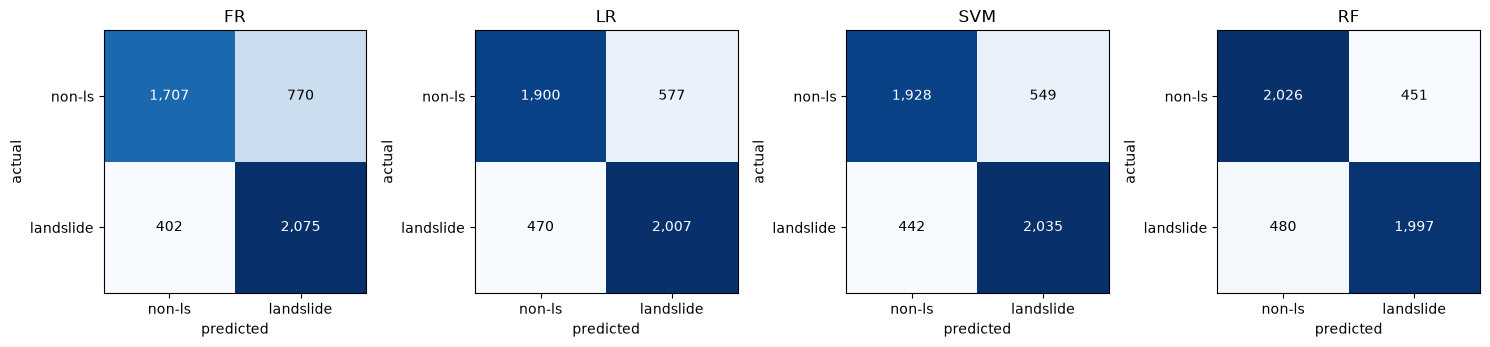

In [67]:
# 5.8 Confusion matrices (pooled, threshold 0.5; FR threshold = neutral index of 1 per factor)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (name, g) in zip(axes, oofA.groupby("model", sort=False)):
    cm = confusion_matrix(g["y"], (g["score"] >= g["threshold"].iloc[0]).astype(int))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["non-ls", "landslide"]); ax.set_yticks([0, 1], ["non-ls", "landslide"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(name)
plt.tight_layout(); plt.savefig(FIG / "fig_confusion_modelA.png", dpi=200); plt.show()

## Step 6. Extra experiments

All experiments use the same leave-one-district-out design as step 5, so their scores are directly comparable.

| # | Experiment | Question |
|---|---|---|
| 1 | **No-shaking ablation:** Model A without `pga_main`, `pga_after`, `pga_sin_slope` | How much does the earthquake signal add beyond terrain and geology? |
| 2 | **1:3 class ratio:** all 7,431 negatives | Do the results hold when non-landslides outnumber landslides? (PR-AUC is the key metric here; a random model scores 0.25.) |
| 3 | **Model A vs Model B:** B is trained on pre-earthquake (rainfall-era) slides without shaking features, then scored on the held-out co-seismic slides and negatives that Model A was tested on | How much would a conventional, rainfall-based susceptibility map miss in an earthquake? |
| 4 | **Bahrabise external test:** train on all districts except Sindhupalchok, test on the independent ICIMOD/SERVIR Bahrabise inventory (551 slides + 551 negatives inside its bounding box, ≥ 150 m from any slide) | Does the model transfer to a separately mapped inventory? Cell 6.8 checks where any loss comes from. |

Runtime about 18 minutes (the 1:3 run takes about 10). Needs step 3 in the same kernel (terrain grid for the Bahrabise features).

In [68]:
# 6.1 Helpers shared by the experiments
assert "terrain" in globals() and "keep_geo" in globals(), "Run step 3 in this kernel first (the Bahrabise test needs its terrain grid)"

SHAKING_USED = ["pga_main", "pga_after", "pga_sin_slope"]
FEATURES_NO_SHAKE = [f for f in FEATURES_NUM if f not in SHAKING_USED]
FR_NO_SHAKE = {k: v for k, v in FR_FACTORS.items() if k != "pga_main"}

def make_dataset(positive_periods, all_negatives=False):
    """Positives from the given periods + the 1:1 negatives (or all 3x negatives), with CV groups."""
    neg = (samples["period"] == "none") & (samples["in_1to1"] | all_negatives)
    d = samples[samples["period"].isin(positive_periods) | neg].copy()
    d["landslide"] = d["period"].isin(positive_periods).astype(int)
    d["cv_group"] = cv_group(d["district"])
    return d

def fit_tuned(name, df, features_num, features_cat=FEATURES_CAT):
    """Grid-search one model with 3-fold GroupKFold on df and return the refitted best pipeline."""
    est, grid = MODELS[name]
    X, y, g = df[features_num + features_cat], df["landslide"].to_numpy(), df["cv_group"].to_numpy()
    pipe = Pipeline([("prep", make_preprocessor(features_num, features_cat)), ("clf", clone(est))])
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=GroupKFold(n_splits=3), n_jobs=-1).fit(X, y, groups=g)
    if name == "SVM":
        return CalibratedClassifierCV(clone(search.best_estimator_), method="sigmoid", ensemble=False).fit(X, y)
    return search.best_estimator_

def run_transfer_cv(train_df, test_sets, features_num, fr_factors, label=""):
    """Leave-one-district-out: train on train_df without district k, score every test set's rows from district k."""
    oof = []
    for k in sorted(train_df["cv_group"].unique()):
        tr = train_df[train_df["cv_group"] != k]
        fitted = {name: fit_tuned(name, tr, features_num) for name in MODELS}
        for set_name, test_df in test_sets.items():
            te = test_df[test_df["cv_group"] == k]
            base = {"idx": te.index, "cv_group": k, "y": te["landslide"].to_numpy(), "test_set": set_name}
            oof.append(pd.DataFrame({**base, "model": "FR", "score": fr_fit_predict(tr, te, fr_factors), "threshold": len(fr_factors)}))
            for name, model in fitted.items():
                oof.append(pd.DataFrame({**base, "model": name, "threshold": 0.5,
                                         "score": model.predict_proba(te[features_num + FEATURES_CAT])[:, 1]}))
        print(f"{label} held out {k:<16} done")
    return pd.concat(oof, ignore_index=True)

print("Features without shaking:", FEATURES_NO_SHAKE)

Features without shaking: ['elevation', 'slope', 'aspect_sin', 'aspect_cos', 'plan_curv', 'profile_curv', 'relief']


In [69]:
# 6.2 Experiment 1, ablation: Model A without any shaking feature (terrain + geology only)
t0 = time.time()
oof_noshake, params_noshake = run_nested_cv(dfA, FEATURES_NO_SHAKE, fr_factors=FR_NO_SHAKE, label="No shaking")
print(f"Time: {(time.time() - t0) / 60:.1f} min")
oof_noshake.to_csv(OUT / "oof_modelA_noshake.csv", index=False)
res_noshake, _ = results_table(oof_noshake)
compare = pd.DataFrame({"AUC_with_shaking": resultsA["ROC_AUC"], "AUC_without_shaking": res_noshake["ROC_AUC"],
                        "PR_AUC_with": resultsA["PR_AUC"], "PR_AUC_without": res_noshake["PR_AUC"]})
compare["AUC_drop"] = compare["AUC_with_shaking"] - compare["AUC_without_shaking"]
compare.round(3)

No shaking fold 1: held out dhading          done
No shaking fold 2: held out dolakha          done
No shaking fold 3: held out gorkha           done
No shaking fold 4: held out kaverpalanchowk  done
No shaking fold 5: held out nuwakot          done
No shaking fold 6: held out ramechhap        done
No shaking fold 7: held out rasuwa           done
No shaking fold 8: held out sindhupalchowk   done
No shaking fold 9: held out small_districts  done
Time: 3.8 min


,AUC_with_shaking,AUC_without_shaking,PR_AUC_with,PR_AUC_without,AUC_drop
FR,0.855,0.809,0.843,0.790,0.046
LR,0.864,0.809,0.843,0.800,0.055
SVM,0.877,0.852,0.860,0.829,0.025
RF,0.890,0.829,0.877,0.815,0.061


In [70]:
# 6.3 Experiment 2, class ratio: 1 landslide : 3 non-landslides (all 7,431 negatives)
dfA3 = make_dataset(["coseis_main", "coseis_after"], all_negatives=True)
print(dfA3["landslide"].value_counts().rename({1: "landslide", 0: "non-landslide"}).to_string())
t0 = time.time()
oof_13, params_13 = run_nested_cv(dfA3, FEATURES_NUM, label="1:3")
print(f"Time: {(time.time() - t0) / 60:.1f} min")
oof_13.to_csv(OUT / "oof_modelA_1to3.csv", index=False)
res_13, _ = results_table(oof_13)
display(res_13.round(3))
print("PR-AUC of a random model at 1:3 = 0.25 (at 1:1 = 0.5). Threshold metrics use 0.5, so recall drops when positives are rarer.")

landslide
non-landslide    7431
landslide        2477
1:3 fold 1: held out dhading          done
1:3 fold 2: held out dolakha          done
1:3 fold 3: held out gorkha           done
1:3 fold 4: held out kaverpalanchowk  done
1:3 fold 5: held out nuwakot          done
1:3 fold 6: held out ramechhap        done
1:3 fold 7: held out rasuwa           done
1:3 fold 8: held out sindhupalchowk   done
1:3 fold 9: held out small_districts  done
Time: 9.0 min


,ROC_AUC,PR_AUC,accuracy,precision,recall,F1,kappa,fold_AUC_mean,fold_AUC_sd
FR,0.852,0.662,0.687,0.438,0.885,0.585,0.377,0.786,0.058
LR,0.872,0.673,0.784,0.545,0.827,0.657,0.509,0.845,0.061
SVM,0.873,0.683,0.829,0.700,0.553,0.618,0.509,0.855,0.068
RF,0.894,0.735,0.832,0.636,0.762,0.693,0.579,0.852,0.068


PR-AUC of a random model at 1:3 = 0.25 (at 1:1 = 0.5). Threshold metrics use 0.5, so recall drops when positives are rarer.


In [71]:
# 6.4 Experiment 3, Model A vs Model B
# Model B = a "rainfall-era" model: trained on PRE-earthquake landslides vs the same negatives, without shaking
# features (no earthquake had happened). In each fold it is scored on its own task (held-out pre-EQ slides) and on
# the co-seismic task (held-out co-seismic slides + the same held-out negatives Model A was tested on).
dfB = make_dataset(["pre"])
print(dfB["landslide"].value_counts().rename({1: "pre-EQ landslide", 0: "non-landslide"}).to_string())
t0 = time.time()
oofB = run_transfer_cv(dfB, {"pre": dfB, "coseismic": dfA}, FEATURES_NO_SHAKE, FR_NO_SHAKE, label="Model B")
print(f"Time: {(time.time() - t0) / 60:.1f} min")
oofB.to_csv(OUT / "oof_modelB.csv", index=False)

resB_pre, _ = results_table(oofB[oofB["test_set"] == "pre"])
resB_co, _ = results_table(oofB[oofB["test_set"] == "coseismic"])
ab = pd.DataFrame({"B_on_preEQ": resB_pre["ROC_AUC"], "B_on_coseismic": resB_co["ROC_AUC"],
                   "A_no_shaking_on_coseismic": res_noshake["ROC_AUC"], "A_on_coseismic": resultsA["ROC_AUC"]})
ab["gap_A_minus_B"] = ab["A_on_coseismic"] - ab["B_on_coseismic"]
ab.to_csv(OUT / "table_modelA_vs_B.csv")
display(ab.round(3))
print("Recall of co-seismic slides at threshold 0.5:  B", resB_co["recall"].round(3).to_dict(), "| A", resultsA["recall"].round(3).to_dict())

landslide
non-landslide       2477
pre-EQ landslide    1857
Model B held out dhading          done
Model B held out dolakha          done
Model B held out gorkha           done
Model B held out kaverpalanchowk  done
Model B held out nuwakot          done
Model B held out ramechhap        done
Model B held out rasuwa           done
Model B held out sindhupalchowk   done
Model B held out small_districts  done
Time: 3.3 min


,B_on_preEQ,B_on_coseismic,A_no_shaking_on_coseismic,A_on_coseismic,gap_A_minus_B
FR,0.622,0.702,0.809,0.855,0.153
LR,0.752,0.781,0.809,0.864,0.083
SVM,0.769,0.781,0.852,0.877,0.097
RF,0.774,0.718,0.829,0.890,0.172


Recall of co-seismic slides at threshold 0.5:  B {'FR': 0.815, 'LR': 0.74, 'SVM': 0.588, 'RF': 0.572} | A {'FR': 0.838, 'LR': 0.81, 'SVM': 0.822, 'RF': 0.806}


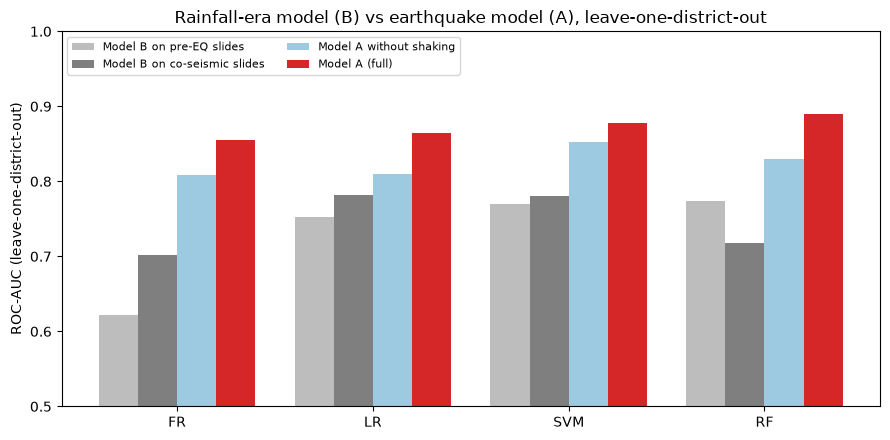

In [72]:
# 6.5 Figure: what the rainfall-era model misses
fig, ax = plt.subplots(figsize=(9, 4.5))
cols = ["B_on_preEQ", "B_on_coseismic", "A_no_shaking_on_coseismic", "A_on_coseismic"]
labels = ["Model B on pre-EQ slides", "Model B on co-seismic slides", "Model A without shaking", "Model A (full)"]
w = 0.2
for i, (c, lab, col) in enumerate(zip(cols, labels, ["#bdbdbd", "#7f7f7f", "#9ecae1", "#d62728"])):
    ax.bar(np.arange(len(ab)) + (i - 1.5) * w, ab[c], w, label=lab, color=col)
ax.set_xticks(range(len(ab)), ab.index); ax.set_ylim(0.5, 1); ax.set_ylabel("ROC-AUC (leave-one-district-out)")
ax.set_title("Rainfall-era model (B) vs earthquake model (A), leave-one-district-out")
ax.legend(fontsize=8, ncol=2, loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "fig_modelA_vs_B.png", dpi=200); plt.show()

In [73]:
# 6.6 Experiment 4, external test on the independent Bahrabise inventory: build the test set
bah = gpd.read_file(OUT / "landslides_clean.gpkg", layer="bahrabise")
bah["geometry"] = bah.geometry.make_valid()
bah_pos = gpd.GeoDataFrame({"ls_type": bah["ls_type"].to_numpy(), "landslide": 1}, geometry=bah.geometry.centroid.to_numpy(), crs=CRS_UTM45)

# Negatives: random points inside the Bahrabise bounding box, on valid terrain, >= 150 m from any slide of either inventory
rng = np.random.default_rng(SEED)
bx0, by0, bx1, by1 = bah.total_bounds
cand = gpd.GeoSeries(gpd.points_from_xy(rng.uniform(bx0, bx1, 5 * len(bah)), rng.uniform(by0, by1, 5 * len(bah))), crs=CRS_UTM45)
cand = cand[np.isfinite(sample_grid(terrain["slope"], cand.x.to_numpy(), cand.y.to_numpy()))]
exclusion = gpd.GeoSeries(pd.concat([all_slides.geometry, bah.geometry], ignore_index=True), crs=CRS_UTM45)
cand = cand.drop(index=cand.index[np.unique(exclusion.sindex.query(cand, predicate="dwithin", distance=NEG_BUFFER_M)[0])])
assert len(cand) >= len(bah_pos), "not enough Bahrabise negatives"
bah_neg = gpd.GeoDataFrame({"ls_type": "none", "landslide": 0}, index=range(len(bah_pos)), geometry=cand.iloc[:len(bah_pos)].to_numpy(), crs=CRS_UTM45)

bah_pts = pd.concat([bah_pos, bah_neg], ignore_index=True)
bah_df = pd.concat([bah_pts.drop(columns="geometry"), extract_features(bah_pts)], axis=1)
bah_df["geology"] = bah_df["geology"].where(bah_df["geology"].isin(keep_geo), "Other")
print(f"Bahrabise test set: {len(bah_pos)} slides + {len(bah_neg)} negatives | missing values: {int(bah_df.isna().sum().sum())}")
display(bah_df.groupby("landslide")[["slope", "relief", "pga_main", "pga_after"]].median().round(1))

Bahrabise test set: 551 slides + 551 negatives | missing values: 0


,slope,relief,pga_main,pga_after
landslide,,,,
0,27.400000,229.399994,59.9,42.3
1,32.200001,282.600006,59.2,42.1


In [74]:
# 6.7 Train on every district EXCEPT Sindhupalchok (Bahrabise lies inside it), then test on Bahrabise
train_ext = dfA[dfA["cv_group"] != "sindhupalchowk"]
print(f"Training points: {len(train_ext):,} ({train_ext['landslide'].sum():,} landslides)")
ext_models = {name: fit_tuned(name, train_ext, FEATURES_NUM) for name in MODELS}
ext_scores = {"FR": (fr_fit_predict(train_ext, bah_df), len(FR_FACTORS))}
for name, model in ext_models.items():
    ext_scores[name] = (model.predict_proba(bah_df[FEATURES_NUM + FEATURES_CAT])[:, 1], 0.5)
res_ext = pd.DataFrame({m: metrics(bah_df["landslide"], s, t) for m, (s, t) in ext_scores.items()}).T
res_ext.to_csv(OUT / "table_bahrabise.csv")
display(res_ext.round(3))

# Recall by landslide type (share of each type predicted as landslide)
is_ls = bah_df["landslide"] == 1
by_type = pd.DataFrame({m: pd.Series(s[is_ls] >= t, index=bah_df.index[is_ls]).groupby(bah_df.loc[is_ls, "ls_type"]).mean()
                        for m, (s, t) in ext_scores.items()})
by_type["n"] = bah_df.loc[is_ls, "ls_type"].value_counts()
print("Recall by Bahrabise landslide type:")
by_type.round(3)

Training points: 3,638 (1,491 landslides)


,ROC_AUC,PR_AUC,accuracy,precision,recall,F1,kappa
FR,0.606,0.628,0.530,0.520,0.760,0.618,0.060
LR,0.587,0.585,0.555,0.550,0.610,0.578,0.111
SVM,0.639,0.633,0.593,0.593,0.588,0.591,0.185
RF,0.665,0.685,0.624,0.614,0.668,0.640,0.249


Recall by Bahrabise landslide type:


,FR,LR,SVM,RF,n
ls_type,,,,,
all,0.833,0.667,0.000,0.333,6
coll,0.800,0.680,0.653,0.760,75
debris,0.746,0.587,0.587,0.662,201
rf,0.920,0.724,0.690,0.736,87
rsl,0.681,0.549,0.533,0.615,182


In [75]:
# 6.8 Why is the external AUC lower? Swap the positives and the negatives (2 x 2 check, same models as 6.7)
# Positives: Bahrabise slides, or ICIMOD co-seismic slides inside the same box (both unseen in training).
# Negatives: local points inside the Bahrabise box, or the 1:1 negatives spread over all of Sindhupalchok.
cols = FEATURES_NUM + FEATURES_CAT
in_box = dfA["x"].between(bx0, bx1) & dfA["y"].between(by0, by1)
pos_sets = {"Bahrabise slides": bah_df[bah_df["landslide"] == 1], "ICIMOD slides in box": dfA[in_box & (dfA["landslide"] == 1)]}
neg_sets = {"local box negatives": bah_df[bah_df["landslide"] == 0],
            "Sindhupalchok-wide negatives": dfA[(dfA["cv_group"] == "sindhupalchowk") & (dfA["landslide"] == 0)]}
rows = []
for pn, P in pos_sets.items():
    for nn, N in neg_sets.items():
        X = pd.concat([P[cols], N[cols]]); y = np.r_[np.ones(len(P)), np.zeros(len(N))]
        rows.append({"positives": f"{pn} (n={len(P)})", "negatives": f"{nn} (n={len(N)})",
                     **{m: roc_auc_score(y, mdl.predict_proba(X)[:, 1]) for m, mdl in ext_models.items()}})
diag = pd.DataFrame(rows).set_index(["positives", "negatives"])
diag.to_csv(OUT / "table_bahrabise_diagnostic.csv")
display(diag.round(3))
print("Median terrain and shaking of the two positive sets and the local negatives:")
pd.DataFrame({k: v[["slope", "relief", "elevation", "pga_main", "pga_after"]].median()
              for k, v in {**pos_sets, "local box negatives": neg_sets["local box negatives"]}.items()}).round(1)

LR  \
positives                    negatives                                     
Bahrabise slides (n=551)     local box negatives (n=551)           0.587   
                             Sindhupalchok-wide negatives (n=330)  0.629   
ICIMOD slides in box (n=297) local box negatives (n=551)           0.778   
                             Sindhupalchok-wide negatives (n=330)  0.798   

                                                                     SVM  \
positives                    negatives                                     
Bahrabise slides (n=551)     local box negatives (n=551)           0.639   
                             Sindhupalchok-wide negatives (n=330)  0.687   
ICIMOD slides in box (n=297) local box negatives (n=551)           0.814   
                             Sindhupalchok-wide negatives (n=330)  0.846   

                                                                      RF  
positives                    negatives                                    
Bahrabise slides (n=551)     local box negatives (n=551)           0.665  
                             Sindhupalchok-wide negatives (n=330)  0.720  
ICIMOD slides in box (n=297) local box negatives (n=551)           0.838  
                             Sindhupalchok-wide negatives (n=330)  0.885

Median terrain and shaking of the two positive sets and the local negatives:


,Bahrabise slides,ICIMOD slides in box,local box negatives
slope,32.2,37.0,27.4
relief,282.6,303.8,229.4
elevation,1838.0,1733.4,2051.2
pga_main,59.2,60.4,59.9
pga_after,42.1,43.1,42.3


In [76]:
# 6.9 Summary of all experiments (pooled ROC-AUC / PR-AUC / F1 / kappa)
summary = pd.concat({
    "A: main (1:1)": resultsA, "A: no shaking": res_noshake, "A: 1:3 ratio": res_13,
    "B: pre-EQ task": resB_pre, "B: co-seismic task": resB_co, "A: Bahrabise external": res_ext,
}, names=["experiment", "model"])[["ROC_AUC", "PR_AUC", "F1", "kappa"]]
summary.to_csv(OUT / "table_experiments.csv")
summary["ROC_AUC"].unstack().reindex(columns=["FR", "LR", "SVM", "RF"]).round(3)

model,FR,LR,SVM,RF
experiment,,,,
A: main (1:1),0.855,0.864,0.877,0.890
A: no shaking,0.809,0.809,0.852,0.829
A: 1:3 ratio,0.852,0.872,0.873,0.894
B: pre-EQ task,0.622,0.752,0.769,0.774
B: co-seismic task,0.702,0.781,0.781,0.718
A: Bahrabise external,0.606,0.587,0.639,0.665


## Step 7. SHAP explanations and susceptibility map

1. **Final model:** Random Forest (best pooled AUC in step 5) trained on all Model A data, with hyperparameters re-tuned by the same district-grouped search.
2. **SHAP** (TreeExplainer, 1,000 random points): global importance, the direction of each feature's effect, and slope × shaking dependence plots.
3. **Susceptibility map:** probability for all 2.6 million valid 90 m cells. Shaking is interpolated at cell centres and geology polygons are burned onto the grid with the same class grouping as cell 3.7. Classes are defined by share of area: **Low 40% · Moderate 30% · High 20% · Very High 10%**. Saved as `outputs/susceptibility_probability.tif` and `outputs/susceptibility_class.tif` (UTM 45N) plus a PNG.
4. **Honest validation of the map.** A Random Forest fits its own training points almost perfectly, so the success-rate curve (training slides on the final map) only shows goodness of fit. Predictive skill comes from a **validation map** trained the same way **without Sindhupalchok**: on it, Sindhupalchok's 986 co-seismic slides and the 551 Bahrabise slides are unseen. Prediction-rate curves and class shares use that map.

Runtime about 3 minutes. Needs steps 3–6 in the same kernel.

In [77]:
# 7.1 Final model: Random Forest (best pooled AUC in step 5) trained on all Model A data
# Hyperparameters are re-tuned with the same 3-fold district-grouped search used inside the CV
import shap
from pyproj import Transformer
from rasterio.features import rasterize
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

t0 = time.time()
final_rf = fit_tuned("RF", dfA, FEATURES_NUM)
print("Chosen hyperparameters:", {k: final_rf.get_params()[f"clf__{k}"] for k in ["max_depth", "min_samples_leaf", "max_features"]},
      f"| fitted in {time.time() - t0:.0f} s")

Chosen hyperparameters: {'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt'} | fitted in 23 s


In [78]:
# 7.2 SHAP values (TreeExplainer) for 1,000 random training points
prep, rf = final_rf.named_steps["prep"], final_rf.named_steps["clf"]
shap_X = dfA.sample(1000, random_state=SEED)
Xt = prep.transform(shap_X[FEATURES_NUM + FEATURES_CAT])
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt

t0 = time.time()
sv = shap.TreeExplainer(rf).shap_values(Xt)
sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if sv.ndim == 3 else sv)   # SHAP for the "landslide" class
shap_num = pd.DataFrame(sv[:, :len(FEATURES_NUM)], columns=FEATURES_NUM, index=shap_X.index)
shap_num["geology"] = sv[:, len(FEATURES_NUM):].sum(axis=1)   # one-hot geology columns summed into one effect
importance = shap_num.abs().mean().sort_values(ascending=False).rename("mean_abs_SHAP")
importance.to_csv(OUT / "table_shap_importance.csv")
print(f"SHAP computed in {time.time() - t0:.0f} s")
importance.round(4)

SHAP computed in 70 s


pga_sin_slope    0.1117
pga_main         0.1004
slope            0.0557
relief           0.0479
elevation        0.0464
profile_curv     0.0381
geology          0.0362
pga_after        0.0270
plan_curv        0.0190
aspect_cos       0.0170
aspect_sin       0.0161
Name: mean_abs_SHAP, dtype: float64

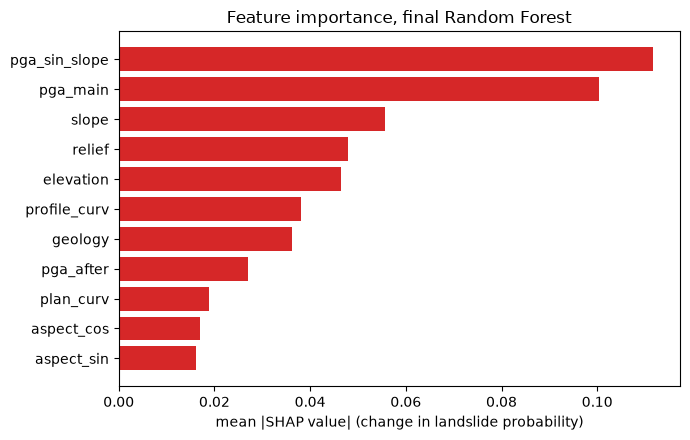

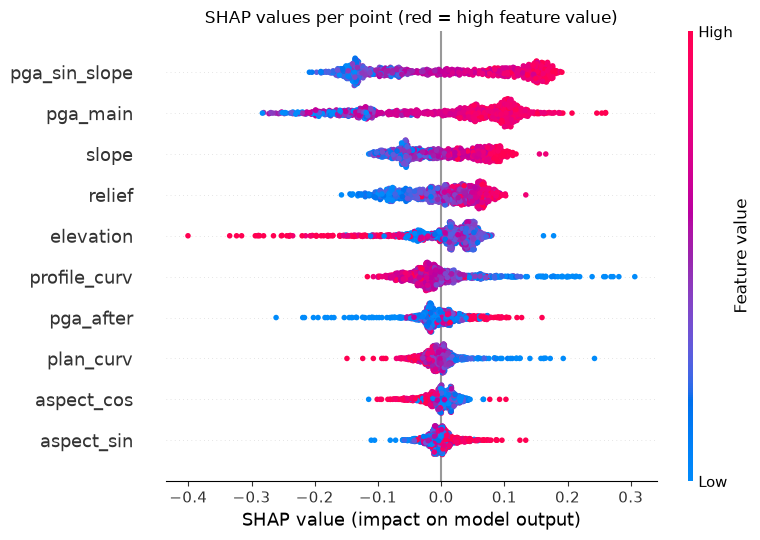

In [79]:
# 7.3 SHAP figures: global importance and direction of each feature's effect
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index[::-1], importance.values[::-1], color="#d62728")
ax.set_xlabel("mean |SHAP value| (change in landslide probability)"); ax.set_title("Feature importance, final Random Forest")
plt.tight_layout(); plt.savefig(FIG / "fig_shap_importance.png", dpi=200); plt.show()

plt.figure()   # shap draws on the current figure, so start a fresh one
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)   # shap's internal use of np.random.seed
    shap.summary_plot(shap_num[FEATURES_NUM].to_numpy(), shap_X[FEATURES_NUM], show=False, plot_size=(8, 5.5))
plt.title("SHAP values per point (red = high feature value)")
plt.tight_layout(); plt.savefig(FIG / "fig_shap_beeswarm.png", dpi=200); plt.show()

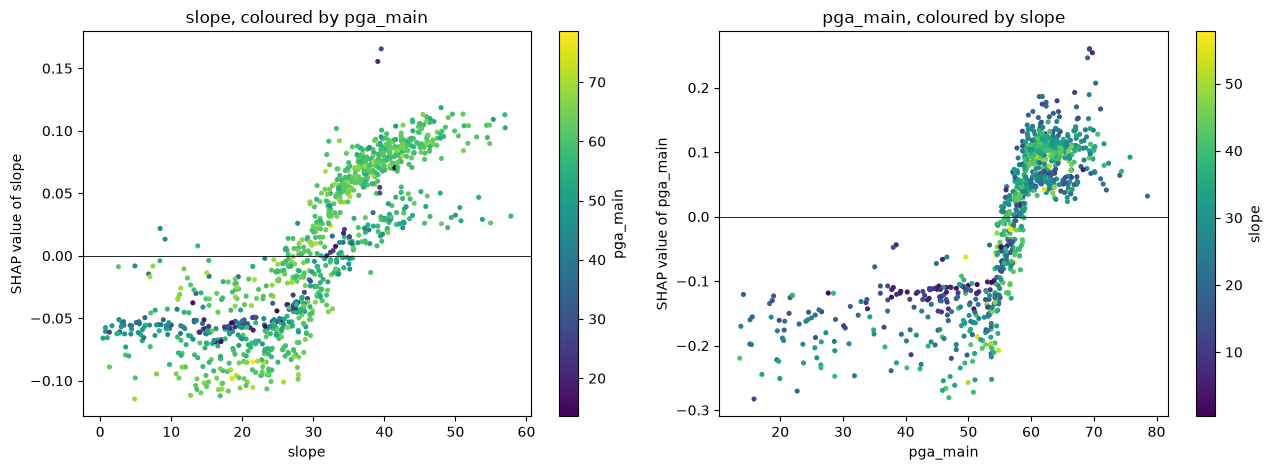

In [80]:
# 7.4 SHAP dependence: how slope and shaking interact
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (f, colour_by) in zip(axes, [("slope", "pga_main"), ("pga_main", "slope")]):
    sc = ax.scatter(shap_X[f], shap_num[f], c=shap_X[colour_by], s=7, cmap="viridis")
    plt.colorbar(sc, ax=ax, label=colour_by)
    ax.axhline(0, color="k", lw=.6)
    ax.set_xlabel(f); ax.set_ylabel(f"SHAP value of {f}"); ax.set_title(f"{f}, coloured by {colour_by}")
plt.tight_layout(); plt.savefig(FIG / "fig_shap_dependence.png", dpi=200); plt.show()

In [81]:
# 7.5 Predict landslide probability for every valid 90 m cell of the study area
rows, cols = np.nonzero(valid)
cx, cy = xmin + (cols + 0.5) * RES, ymax - (rows + 0.5) * RES
lon, lat = Transformer.from_crs(CRS_UTM45, CRS_WGS84, always_xy=True).transform(cx, cy)

grid_df = pd.DataFrame({k: terrain[k][rows, cols] for k in TERRAIN})
for k in ["pga_main", "pga_after"]:
    grid_df[k] = SHAKE[k](np.c_[lat, lon])
grid_df["pga_sin_slope"] = grid_df[["pga_main", "pga_after"]].max(axis=1) / 100 * np.sin(np.radians(grid_df["slope"]))

# Geology: burn the polygons onto the grid (code 0 = no polygon), then apply the same grouping as cell 3.7
geo_names = np.array(["No Data"] + geol["CLASS"].fillna("").replace("", "No Data").tolist())
geo_code = rasterize(((g, i + 1) for i, g in enumerate(geol.geometry)), out_shape=valid.shape,
                     transform=GRID_TRANSFORM, fill=0, dtype="int32")
cell_geo = pd.Series(geo_names[geo_code[rows, cols]])
grid_df["geology"] = cell_geo.where(cell_geo.isin(keep_geo), "Other").to_numpy()
assert grid_df.isna().sum().sum() == 0, "missing values in the grid features"

def predict_grid(model, chunk=500_000):
    """Landslide probability for every valid cell: returns (1-D array over valid cells, 2-D map with NaN outside)."""
    model.set_params(clf__n_jobs=-1)   # use all cores for prediction
    p = np.concatenate([model.predict_proba(grid_df.iloc[i:i + chunk][FEATURES_NUM + FEATURES_CAT])[:, 1]
                        for i in range(0, len(grid_df), chunk)])
    m = np.full(valid.shape, np.nan, dtype="float32")
    m[rows, cols] = p
    return p, m

t0 = time.time()
prob, prob_map = predict_grid(final_rf)
print(f"Predicted {len(prob):,} cells in {time.time() - t0:.0f} s | probability median {np.median(prob):.3f}")

# Check: the map at the training points should agree with predicting the points directly
direct = final_rf.predict_proba(dfA[FEATURES_NUM + FEATURES_CAT])[:, 1]
from_map = sample_grid(prob_map, dfA["x"].to_numpy(), dfA["y"].to_numpy())
print(f"Map vs direct prediction at training points: r = {np.corrcoef(direct, from_map)[0, 1]:.3f}, "
      f"median |difference| = {np.median(np.abs(direct - from_map)):.3f}")

Predicted 2,612,676 cells in 16 s | probability median 0.144
Map vs direct prediction at training points: r = 1.000, median |difference| = 0.000


Probability cut-offs (Low|Moderate|High|Very High): [0.096 0.3   0.619]
Saved susceptibility_probability.tif and susceptibility_class.tif to D:\Softwarica\Projects\Gorkha Earthquake Project\outputs


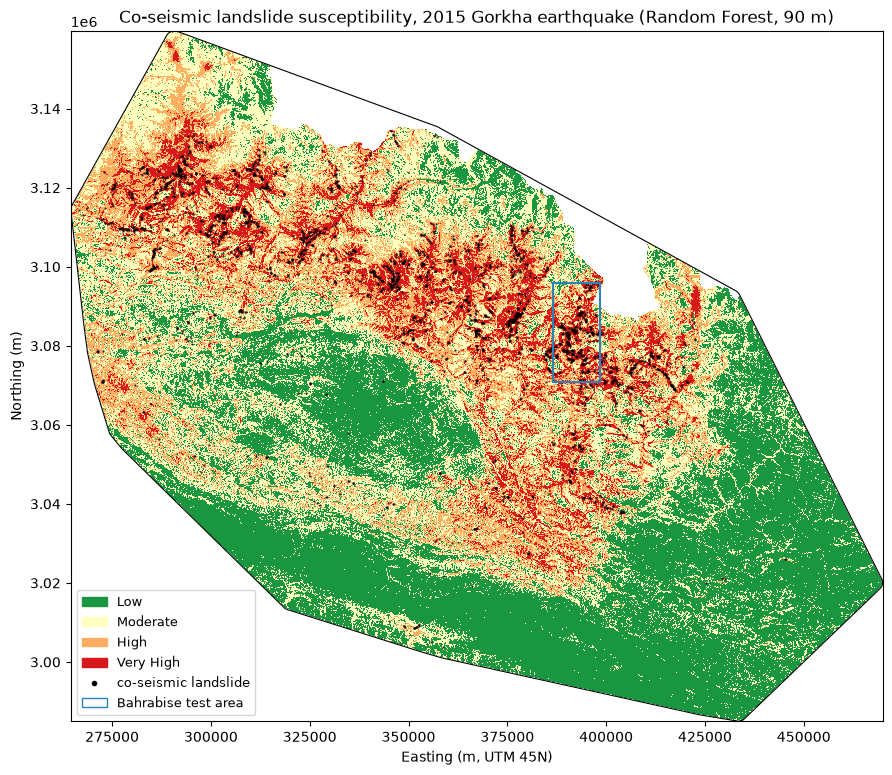

In [82]:
# 7.6 Four susceptibility classes by share of area: Low 40% | Moderate 30% | High 20% | Very High 10%
CLASS_NAMES = ["Low", "Moderate", "High", "Very High"]
CLASS_COLORS = ["#1a9641", "#ffffbf", "#fdae61", "#d7191c"]
cuts = np.quantile(prob, [0.4, 0.7, 0.9])
print("Probability cut-offs (Low|Moderate|High|Very High):", np.round(cuts, 3))
def classify(p):
    """Class map (1-4, 0 = no data) using this map's own area-share cut-offs."""
    m = np.zeros(valid.shape, dtype="uint8")
    m[rows, cols] = np.digitize(p, np.quantile(p, [0.4, 0.7, 0.9])) + 1
    return m
cls_map = classify(prob)

profile = dict(driver="GTiff", width=WIDTH, height=HEIGHT, count=1, crs=CRS_UTM45, transform=GRID_TRANSFORM, compress="deflate")
with rasterio.open(OUT / "susceptibility_probability.tif", "w", dtype="float32", nodata=np.nan, **profile) as dst:
    dst.write(prob_map, 1)
with rasterio.open(OUT / "susceptibility_class.tif", "w", dtype="uint8", nodata=0, **profile) as dst:
    dst.write(cls_map, 1)
    dst.write_colormap(1, {i + 1: tuple(int(c[j:j + 2], 16) for j in (1, 3, 5)) + (255,) for i, c in enumerate(CLASS_COLORS)})
print("Saved susceptibility_probability.tif and susceptibility_class.tif to", OUT)

fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(np.ma.masked_equal(cls_map, 0), extent=extent, cmap=ListedColormap(CLASS_COLORS), vmin=.5, vmax=4.5, interpolation="nearest")
co = dfA[dfA["landslide"] == 1]
ax.scatter(co["x"], co["y"], s=.6, c="k", alpha=.6)
ax.plot(*study.exterior.xy, "k-", lw=.8)
ax.add_patch(plt.Rectangle((bx0, by0), bx1 - bx0, by1 - by0, fill=False, ec="#2b83ba", lw=1.5))
handles = [Patch(color=c, label=n) for c, n in zip(CLASS_COLORS, CLASS_NAMES)]
handles += [plt.Line2D([], [], ls="", marker=".", color="k", label="co-seismic landslide"),
            Patch(fill=False, ec="#2b83ba", label="Bahrabise test area")]
ax.legend(handles=handles, loc="lower left", fontsize=9)
ax.set_title("Co-seismic landslide susceptibility, 2015 Gorkha earthquake (Random Forest, 90 m)")
ax.set_xlabel("Easting (m, UTM 45N)"); ax.set_ylabel("Northing (m)"); ax.set_aspect("equal")
plt.tight_layout(); plt.savefig(FIG / "fig_susceptibility_map.png", dpi=250); plt.show()

Validation map done in 24 s


,area_pct,heldout_sindhupalchok_pct,bahrabise_pct,training_slides_final_map_pct
Low,40.0,0.2,5.1,0.0
Moderate,30.0,6.9,17.4,0.0
High,20.0,24.5,21.8,0.8
Very High,10.0,68.4,55.7,99.2


Unseen slides in High or Very High (validation map): Sindhupalchok 92.9%, Bahrabise 77.5%  (success criterion >= 60%)


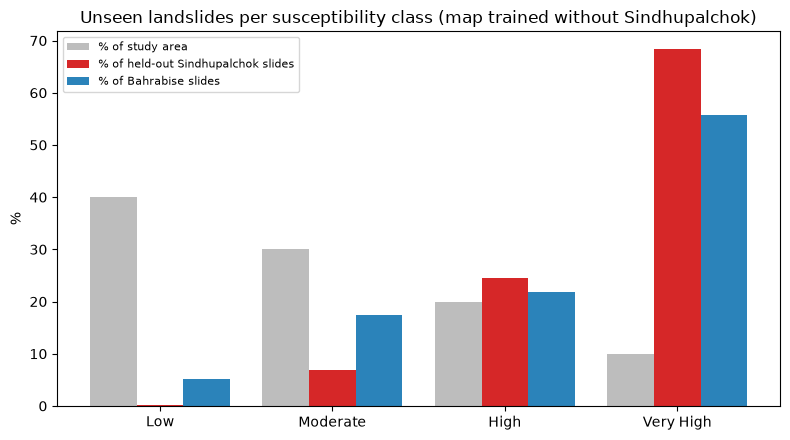

In [83]:
# 7.7 Validation map: the final model has seen every ICIMOD slide (and Random Forests fit their training points
# almost perfectly), so it cannot be validated on them. Instead, retrain the same way WITHOUT Sindhupalchok and
# map again: the 986 ICIMOD co-seismic slides of Sindhupalchok and the 551 Bahrabise slides are then unseen.
t0 = time.time()
val_rf = fit_tuned("RF", dfA[dfA["cv_group"] != "sindhupalchowk"], FEATURES_NUM)
prob_val, prob_val_map = predict_grid(val_rf)
cls_val = classify(prob_val)
print(f"Validation map done in {time.time() - t0:.0f} s")

co = dfA[dfA["landslide"] == 1]
held = co[co["cv_group"] == "sindhupalchowk"]
bz = bah_df[bah_df["landslide"] == 1]

def class_shares(cmap, pts):
    c = sample_grid(cmap.astype("float32"), pts["x"].to_numpy(), pts["y"].to_numpy())
    return pd.Series(c).value_counts(normalize=True).reindex([1, 2, 3, 4], fill_value=0).to_numpy() * 100

class_stats = pd.DataFrame({"area_pct": [40.0, 30.0, 20.0, 10.0],
                            "heldout_sindhupalchok_pct": class_shares(cls_val, held),
                            "bahrabise_pct": class_shares(cls_val, bz),
                            "training_slides_final_map_pct": class_shares(cls_map, co)}, index=CLASS_NAMES)
class_stats.to_csv(OUT / "table_susceptibility_classes.csv")
display(class_stats.round(1))
hv = class_stats.loc[["High", "Very High"]].sum()
print(f"Unseen slides in High or Very High (validation map): Sindhupalchok {hv['heldout_sindhupalchok_pct']:.1f}%, "
      f"Bahrabise {hv['bahrabise_pct']:.1f}%  (success criterion >= 60%)")

fig, ax = plt.subplots(figsize=(8, 4.5))
w = .27
for i, (col, lab, c) in enumerate([("area_pct", "% of study area", "#bdbdbd"),
                                   ("heldout_sindhupalchok_pct", "% of held-out Sindhupalchok slides", "#d62728"),
                                   ("bahrabise_pct", "% of Bahrabise slides", "#2b83ba")]):
    ax.bar(np.arange(4) + (i - 1) * w, class_stats[col], w, label=lab, color=c)
ax.set_xticks(range(4), CLASS_NAMES); ax.set_ylabel("%"); ax.legend(fontsize=8)
ax.set_title("Unseen landslides per susceptibility class (map trained without Sindhupalchok)")
plt.tight_layout(); plt.savefig(FIG / "fig_class_shares.png", dpi=200); plt.show()

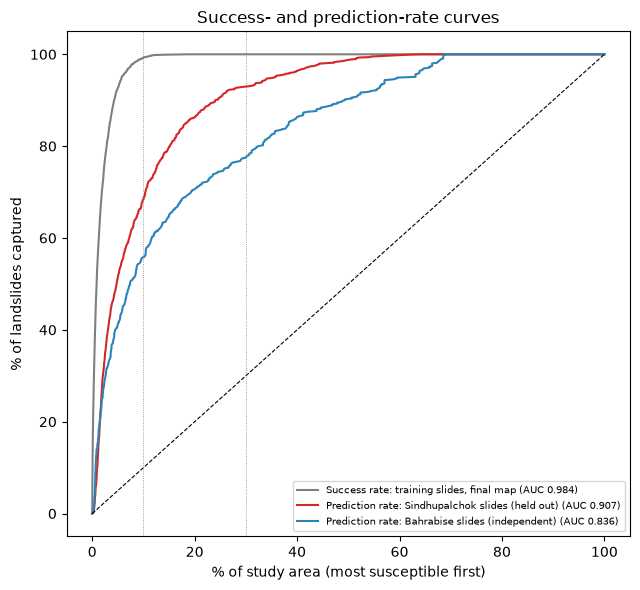

,n_slides,AUC,captured_in_top10pct_area,captured_in_top30pct_area
curve,,,,
"Success rate: training slides, final map",2477,0.984,99.233,100.000
Prediction rate: Sindhupalchok slides (held out),986,0.907,68.357,92.901
Prediction rate: Bahrabise slides (independent),551,0.836,55.717,77.495


In [84]:
# 7.8 Success-rate curve (training slides on the final map) and prediction-rate curves (unseen slides on the validation map)
def rate_curve(p_all, p_slides):
    """For each slide: share of the study area at least as susceptible as its cell; returns the sorted curve."""
    s = np.sort(p_all)
    area = np.sort(1 - np.searchsorted(s, p_slides, side="left") / len(s))
    return area, np.arange(1, len(area) + 1) / len(area)

curves = {"Success rate: training slides, final map": (prob, prob_map, co, "#7f7f7f"),
          "Prediction rate: Sindhupalchok slides (held out)": (prob_val, prob_val_map, held, "#d62728"),
          "Prediction rate: Bahrabise slides (independent)": (prob_val, prob_val_map, bz, "#2b83ba")}
fig, ax = plt.subplots(figsize=(6.5, 6))
rate_rows = []
for name, (p_all, p_map, pts, c) in curves.items():
    area, frac = rate_curve(p_all, sample_grid(p_map, pts["x"].to_numpy(), pts["y"].to_numpy()))
    auc = 1 - area.mean()
    ax.plot(np.r_[0, area, 1] * 100, np.r_[0, frac, 1] * 100, color=c, label=f"{name} (AUC {auc:.3f})")
    rate_rows.append({"curve": name, "n_slides": len(pts), "AUC": auc,
                      "captured_in_top10pct_area": (area <= .1).mean() * 100, "captured_in_top30pct_area": (area <= .3).mean() * 100})
ax.plot([0, 100], [0, 100], "k--", lw=.8)
for a in (10, 30):
    ax.axvline(a, color="grey", lw=.6, ls=":")
ax.set_xlabel("% of study area (most susceptible first)"); ax.set_ylabel("% of landslides captured")
ax.set_title("Success- and prediction-rate curves"); ax.legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "fig_rate_curves.png", dpi=200); plt.show()
rates = pd.DataFrame(rate_rows).set_index("curve")
rates.to_csv(OUT / "table_rate_curves.csv")
rates.round(3)